# Task 2: Model Baseline and Data Preparation
## Air Quality Sensor Calibration · WS 2026/27 · Revision mit Task 1

**Ziel:** `pm25_target` in µg/m³ mit linearer Regression schätzen und die Wirkung begründeter Vorbereitungsschritte prüfen.

Grundlage: Case Study, Python Labs, Vorlesungen, altes Projekt samt Feedback sowie **Aufgabe_1_Data_Science_80_20_ohne_Holdout.ipynb** und der ergänzende Tipp zur Winsorisierung. Keine externen fachlichen Quellen.

**Neu:** exakt derselbe 80/20-Split wie Task 1; obere Winsorisierung für `pm25_lowcost`; negative Schadstoffwerte entweder durch P5 gültiger Trainingswerte ersetzen oder imputieren; vollständiger Vergleich von 144 Varianten.

Das alte Projekt liefert die modulare Struktur, nicht dessen Bike-Rental-Regeln. Eine Zuordnung aller Bausteine und Anpassungen steht in `QUELLEN_UND_ENTSCHEIDUNGEN.md`.

## 1. Anschluss an Task 1 und verbindliche Regeln

Task 1 zeigt 461 fehlende Low-cost-Messungen, einen Maximalwert von 595,53 µg/m³ und negative NO-Werte bis −2,7. Das begründet Imputation, obere Winsorisierung und eine gesonderte Negativwertbehandlung. Die Überschrift „Interpretation für Aufgabe 2“ in Task 1 enthält bislang nur „?“; hier wird die fachliche Überleitung konkretisiert.

- Split wie Task 1, Zelle 14: fehlende Labels aus der **ursprünglichen Trainingsdatei** ausschließen, dann `train_test_split(test_size=0.20, random_state=42)`; 2.727 Training, 682 Validation. Ausschlüsse werden protokolliert. Nach Bildung der Validation keine Zeile löschen. Der offizielle Test bleibt vollständig.
- Alle 16 ursprünglichen Features sind in der Task-2-Baseline repräsentiert. Keine Übernahme der Forward Selection aus Task 1b; die dortige Ein-Feature-Baseline hat einen anderen Zweck.
- Maßgeblich ist Case Study S. 8: gleiche lineare Regression, Training/Validation-Vergleich mit MAE und R², Auswahl auf Validation, abschließender Test, drei CSV-Exporte. Ältere Tipps S. 15 und ihre wiederholte Testauswertung haben keinen Vorrang.
- Labelwerte werden nie imputiert, gekappt, transformiert oder als Prädiktoren verwendet. Alle trainierbaren Vorbereitungsparameter entstehen ausschließlich im Fit-Training.
- Ausgewählt wird das kleinste Validation-MAE. Bis 10⁻⁸ gilt Gleichstand; dann gewinnt die einfachere Vorbereitung. Kein Refit auf Training + Validation, damit die CSVs für Task 3 sauber getrennt bleiben.

**Grenzen der Bewertung:** Der Zufallssplit mischt zeitlich benachbarte Messungen und kann die Übertragbarkeit auf spätere Monate optimistisch darstellen. Task 1 hat dieselbe Validation bereits für Feature-Vergleiche genutzt. Der offizielle Test wurde in Task 1 und der früheren Task-2-Version schon bewertet; er ist deshalb **kein neuer unberührter Holdout**. Die jetzigen Änderungen folgen dem neuen Task-1-Anschluss und dem fachlichen Tipp, nicht einer Optimierung der bekannten Testkennzahlen. Die früheren zeitlichen Split-Ergebnisse sind nicht direkt vergleichbar.

## 2. Imports und Dateien
Die Bibliotheken stammen aus den Python Labs; `Path`, JSON und Prüfungen dienen der reproduzierbaren Organisation. In VS Code den Kernel mit `requirements.txt` verwenden und **Run All** ausführen. Die Rohdaten bleiben unverändert.

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, PowerTransformer, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

BASE = Path.cwd()
if not (BASE / 'data' / 'pm25_train.csv').exists():
    BASE = BASE / 'Task2_Data_Preparation'
DATA = BASE / 'data'
RESULTS = BASE / 'results'
FIGURES = BASE / 'figures'
RESULTS.mkdir(exist_ok=True)
FIGURES.mkdir(exist_ok=True)
TARGET = 'pm25_target'
plt.rcParams.update({'figure.dpi': 120, 'font.size': 10})
pd.set_option('display.max_columns', 20)
print('Python:', sys.version.split()[0])
print('Arbeitsordner:', BASE)

Python: 3.12.14
Arbeitsordner: /Users/kevin/Documents/ChatGPT/Data Science Projekt/Task2_Data_Preparation


## 3. Exakter Split wie Task 1
Quelle: Task-1-Notebook Zellen 14–16; altes Projekt und Pipeline-Lab. Die Reihenfolge der Zeilen wird vor dem Split nicht verändert. Die exportierten Manifeste dokumentieren die ursprünglichen 0-basierten CSV-Zeilennummern.

In [2]:
original_train = pd.read_csv(DATA / 'pm25_train.csv')
assert original_train.shape == (3613, 17)
labeled = original_train.dropna(subset=[TARGET]).copy()
training, validation = train_test_split(labeled, test_size=0.20, random_state=42)
training, validation = training.copy(), validation.copy()
validation_labels_before = validation[TARGET].copy()
validation_index_before = validation.index.copy()
FEATURES = [c for c in original_train.columns if c != TARGET]
SENSOR_FEATURES = [c for c in FEATURES if c not in ['timestamp', 'year_month']]
assert len(FEATURES) == 16 and len(SENSOR_FEATURES) == 14
assert (len(training), len(validation)) == (2727, 682)
assert set(training.index).isdisjoint(validation.index)
# Die unabhängig aus Task 1 reproduzierten Indizes werden als Referenz mitgeliefert.
expected_split = pd.read_csv(BASE / 'sources' / 'task1_split_manifest.csv')
for name, frame in [('train', training), ('validation', validation)]:
    assert frame.index.tolist() == expected_split.loc[expected_split['split'].eq(name), 'source_row'].tolist()
validation_labels_before = validation[TARGET].copy()
split_summary = pd.DataFrame([
    {'Teil': 'Originaltraining', 'Zeilen': len(original_train), 'Labels vorhanden': original_train[TARGET].notna().sum()},
    {'Teil': 'Training für Fit', 'Zeilen': len(training), 'Labels vorhanden': training[TARGET].notna().sum()},
    {'Teil': 'Validation', 'Zeilen': len(validation), 'Labels vorhanden': validation[TARGET].notna().sum()},
])
display(split_summary)
split_summary.to_csv(RESULTS / 'split_summary.csv', index=False)
pd.DataFrame({'source_row': original_train.index[original_train[TARGET].isna()],
              'reason': 'Label fehlt in ursprünglicher Trainingsdatei; vor Split ausgeschlossen wie Task 1'}).to_csv(RESULTS / 'excluded_training_rows.csv', index=False)

,Teil,Zeilen,Labels vorhanden
0,Originaltraining,3613,3409
1,Training für Fit,2727,2727
2,Validation,682,682


## 4. Datenqualität im Fit-Training
Die Exploration aus Task 1 motiviert die Maßnahmen; numerische Schwellen werden dennoch **neu ausschließlich im Fit-Training** bestimmt. Quellen: Task 1, Pandas Exploration, Missing-Value-Lab, Transformation-Script. Ausreißer sind statistische Auffälligkeiten, keine automatisch nachgewiesenen Messfehler.

In [3]:
diagnosis = training[SENSOR_FEATURES].describe().T
missing = training[SENSOR_FEATURES].isna().sum()
diagnosis['missing_n'] = missing
diagnosis['missing_pct'] = 100 * missing / len(training)
diagnosis['skew'] = training[SENSOR_FEATURES].skew()
q1 = training[SENSOR_FEATURES].quantile(0.25)
q3 = training[SENSOR_FEATURES].quantile(0.75)
iqr = q3 - q1
flagged = (training[SENSOR_FEATURES] < q1 - 1.5 * iqr) | (training[SENSOR_FEATURES] > q3 + 1.5 * iqr)
diagnosis['iqr_flagged_n'] = flagged.sum()
display(diagnosis.round(3))
diagnosis.to_csv(RESULTS / 'training_diagnosis.csv')
print('Doppelte vollständige Trainingszeilen:', training.duplicated().sum())
print('Negative NO-Messwerte:', int((training['no'] < 0).sum()))
print('Label im Training:')
display(training[TARGET].describe().to_frame())

,count,mean,std,min,25%,50%,75%,max,missing_n,missing_pct,skew,iqr_flagged_n
pm25_lowcost,2464.0,5.606,23.888,0.300,1.708,2.750,4.900,595.530,263,9.644,17.685,190
no,2714.0,7.407,41.985,-2.700,0.400,1.600,4.875,1131.700,13,0.477,18.439,315
no2,2714.0,7.966,6.399,0.300,3.600,7.000,10.700,94.800,13,0.477,3.686,67
o3,2141.0,25.866,13.635,0.500,15.100,24.600,35.100,78.600,586,21.489,0.432,4
co2,1971.0,460.206,22.410,427.500,443.050,455.700,473.350,701.200,756,27.723,2.072,23
black_carbon,2727.0,0.887,1.300,0.045,0.354,0.624,1.028,36.684,0,0.000,12.203,174
ufp,2269.0,9452.169,4862.980,2077.700,6384.500,8805.200,11620.000,110138.800,458,16.795,4.947,58
temperature,2415.0,17.450,4.983,5.752,13.963,17.006,20.848,33.166,312,11.441,0.281,14
relative_humidity,2415.0,74.339,14.100,35.542,65.269,77.536,85.709,96.298,312,11.441,-0.740,0
pressure,2415.0,1008.985,7.142,975.475,1004.790,1008.800,1013.406,1030.293,312,11.441,-0.322,63


Doppelte vollständige Trainingszeilen: 0
Negative NO-Messwerte: 376
Label im Training:


,pm25_target
count,2727.000000
mean,3.330480
std,2.206418
min,0.240000
25%,1.745000
50%,2.700000
75%,4.460000
max,14.710000


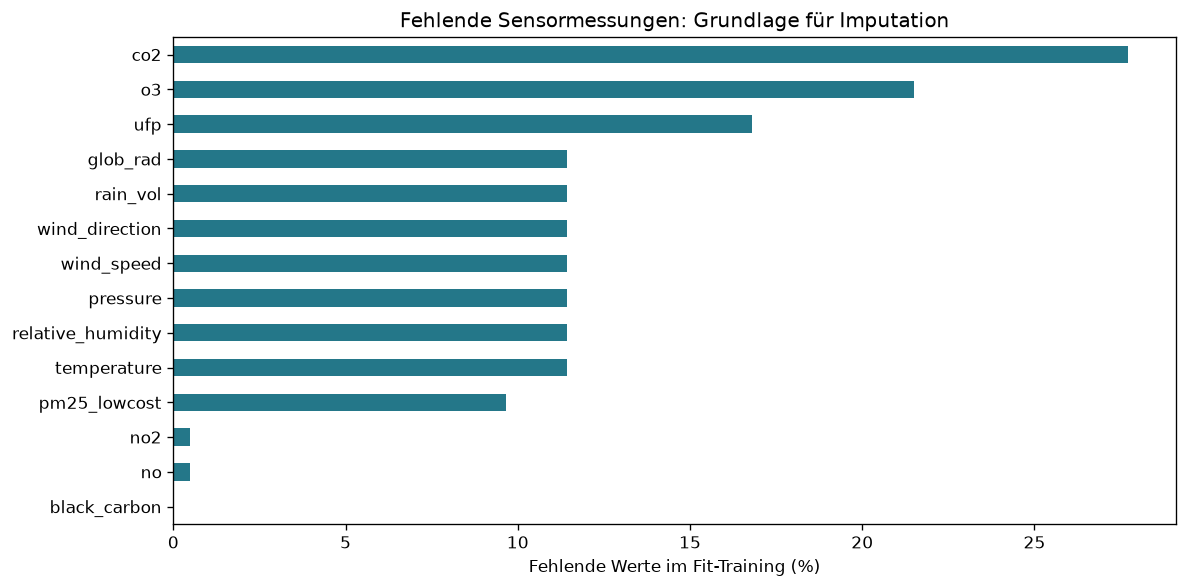

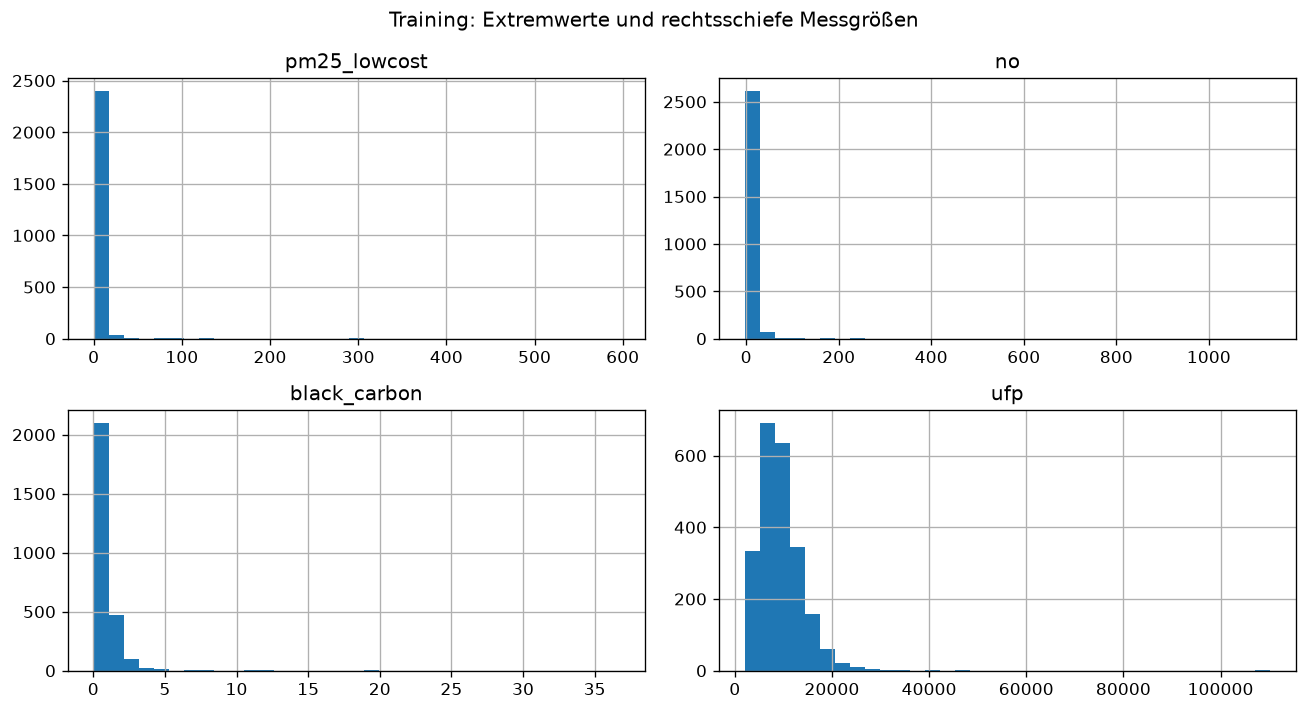

In [4]:
fig, ax = plt.subplots(figsize=(10, 5))
(100 * missing / len(training)).sort_values().plot.barh(ax=ax, color='#247789')
ax.set_xlabel('Fehlende Werte im Fit-Training (%)')
ax.set_title('Fehlende Sensormessungen: Grundlage für Imputation')
fig.tight_layout()
fig.savefig(FIGURES / 'missing_training.png', bbox_inches='tight')
plt.show()
training[['pm25_lowcost', 'no', 'black_carbon', 'ufp']].hist(bins=35, figsize=(11, 6))
plt.suptitle('Training: Extremwerte und rechtsschiefe Messgrößen')
plt.tight_layout()
plt.savefig(FIGURES / 'distributions_training.png', bbox_inches='tight')
plt.show()

## 5. Vorab festgelegter Versuchsraum

| Faktor | Optionen | Begründung |
|---|---|---|
| Imputation | Mittelwert / Median | Fehlende Messungen, Robustheit gegenüber Spitzen |
| Ausreißer | keine / IQR → NaN / Winsor-P95 | Bisherige Lab-Methode mit neuem Tipp vergleichen |
| Negative Schadstoffwerte | unverändert / P5 gültiger Werte / NaN → Imputation | Fehlmessung behandeln, beide besprochenen Varianten prüfen |
| Power | aus / an | Schiefe kontinuierliche Features, keine Normalitätspflicht für OLS |
| Windzyklus | aus / an | Benachbarte Richtungen bei 0°/360° |
| StandardScaler | aus / an | Unterschiedliche Einheiten; erwartete OLS-Invarianz kontrollieren |

**2 × 3 × 3 × 2 × 2 × 2 = 144 Konfigurationen.** Jede Änderung wird einzeln relativ zur Baseline und in allen Kombinationen geprüft. IQR und Winsorisierung sind alternative Verfahren; keine doppelte Spitzenbehandlung.

Der Tipp „Feinstaub“ wird hier auf das Eingabefeature **`pm25_lowcost`** angewendet, nicht auf das Label oder pauschal auf Gase, Black Carbon und UFP. Winsorisierung ersetzt **alle Werte > P95** durch P95; niedrige gültige PM2.5-Werte bleiben erhalten. IQR bleibt als separate Vergleichsvariante auf sieben Schadstofffeatures bestehen.

Die Negativwertregel betrifft nur Schadstoffmessgrößen, nicht etwa zulässige negative Temperaturen. P5 wird aus **vorhandenen, nichtnegativen Trainingswerten** berechnet. Ausschließlich negative Werte werden ersetzt: Das ist kein pauschales Kappen sämtlicher Werte unter P5. Fehlende Werte bleiben bis zur Imputation fehlend.

## 6. Module: minimale Repräsentation und zyklische Windrichtung
Quelle: `pd.to_datetime` aus dem alten Projekt; OHE und Sinus/Cosinus aus `TRANSFORMATION_SCRIPT`; getrenntes Fit/Transform aus Pipeline-Demo. Der Zeitstempel wird als Tage seit Trainingsbeginn dargestellt, nicht als tausende einzelne Kategorien. Sein Informationsgehalt bleibt im Modell; `year_month` bleibt zusätzlich als Kategorie enthalten. Redundanz wird als Grenze dokumentiert, nicht durch Feature Selection beseitigt.

Bei zyklischer Windrichtung werden zuerst Sinus und Cosinus berechnet, danach fehlende Komponenten imputiert. Ein imputierter Vektor darf innerhalb des Einheitskreises liegen; er wird nicht als beobachtete Windrichtung interpretiert.

In [5]:
def represent_features(df, origin, cyclic=False):
    """Deterministische Repräsentation ohne Zugriff auf das Label."""
    X = df[FEATURES].copy()
    timestamp = pd.to_datetime(X['timestamp'])
    X['timestamp_days'] = (timestamp - origin).dt.total_seconds() / 86400
    X = X.drop(columns='timestamp')
    if cyclic:
        X['wind_direction_sin'] = np.sin(2 * np.pi * X['wind_direction'] / 360)
        X['wind_direction_cos'] = np.cos(2 * np.pi * X['wind_direction'] / 360)
        X = X.drop(columns='wind_direction')
    return X

## 7. Module: Negativwerte, Winsorisierung und IQR
Quellen: neue Nutzeranweisung; Outlier-Vorlesung S. 9 (Winsorisierung); Quantile/Masken aus den Labs; IQR aus Pipeline-Demo2. Gegenüber der Demo werden alle Grenzen im Fit gespeichert und später unverändert angewendet.

Reihenfolge: **Repräsentation → Negativwertbehandlung → Ausreißerbehandlung → Imputation → Power → Scaling → OHE**. Ein einmal bestimmtes Trainingsquantil hängt weder von Validierungs-/Testwerten noch von späteren Datenbatches ab.

In [6]:
OUTLIER_FEATURES = ['pm25_lowcost', 'no', 'no2', 'o3', 'co2', 'black_carbon', 'ufp']
NEGATIVE_FEATURES = OUTLIER_FEATURES.copy()

def fit_negative_bounds(X):
    valid = X[NEGATIVE_FEATURES].where(X[NEGATIVE_FEATURES] >= 0)
    bounds = valid.quantile(0.05)
    assert bounds.notna().all() and (bounds >= 0).all()
    return bounds

def apply_negative_values(X, method, bounds):
    X = X.copy()
    if method == 'p05':
        for col in NEGATIVE_FEATURES:
            X.loc[X[col] < 0, col] = bounds[col]
    elif method == 'impute':
        X[NEGATIVE_FEATURES] = X[NEGATIVE_FEATURES].mask(X[NEGATIVE_FEATURES] < 0, np.nan)
    return X

def fit_outliers(X):
    Q1 = X[OUTLIER_FEATURES].quantile(0.25)
    Q3 = X[OUTLIER_FEATURES].quantile(0.75)
    IQR = Q3 - Q1
    return pd.DataFrame({'lower': Q1 - 1.5 * IQR, 'upper': Q3 + 1.5 * IQR})

def apply_outliers(X, bounds):
    X = X.copy()
    values = X[bounds.index]
    mask = (values < bounds['lower']) | (values > bounds['upper'])
    X[bounds.index] = values.mask(mask, np.nan)
    return X

def apply_value_treatments(X, state):
    X = apply_negative_values(X, state['config']['negative'], state['negative_bounds'])
    if state['config']['outliers'] == 'iqr':
        X = apply_outliers(X, state['bounds'])
    elif state['config']['outliers'] == 'winsor95':
        X = X.copy()
        X.loc[X['pm25_lowcost'] > state['winsor95'], 'pm25_lowcost'] = state['winsor95']
    return X

quantile_audit = pd.DataFrame({
    'negative_n': (training[NEGATIVE_FEATURES] < 0).sum(),
    'p05_unfiltered': training[NEGATIVE_FEATURES].quantile(0.05),
    'p05_nonnegative': fit_negative_bounds(training),
})
display(quantile_audit)
print('PM2.5 Trainings-P95:', training['pm25_lowcost'].quantile(0.95))
quantile_audit.to_csv(RESULTS / 'negative_quantile_audit.csv')
# Erwarteter kritischer Befund: ungefiltertes NO-P5 selbst negativ.
assert quantile_audit.loc['no','p05_unfiltered'] < 0
assert quantile_audit.loc['no','p05_nonnegative'] >= 0

,negative_n,p05_unfiltered,p05_nonnegative
pm25_lowcost,0,0.8415,0.8415
no,376,-0.6000,0.1000
no2,0,1.2000,1.2000
o3,0,5.8000,5.8000
co2,0,434.7500,434.7500
black_carbon,0,0.1446,0.1446
ufp,0,3674.2800,3674.2800


PM2.5 Trainings-P95: 11.315499999999997


## 8. Module: Vorbereitung fitten und unverändert anwenden
Quelle: `SimpleImputer`, `OneHotEncoder(handle_unknown='ignore')` und getrenntes Fit/Transform aus Pipeline-Demo; `PowerTransformer(standardize=False)` aus Transformation-Script; `StandardScaler` aus Scaling-Lab. `drop='first'` übernimmt die Referenzkategorie aus dem alten Projekt/Transformation-Lab. `sparse_output=False` ist eine technische API-Anpassung für einen lesbaren DataFrame.

Die Power-Spalten werden einmalig anhand des Fit-Trainings festgelegt: absolute Schiefe > 1, nur Messgrößen, ohne Windrichtung. Dieselben Spalten gelten für alle Power-Varianten. Der Schwellenwert ist eine offengelegte Arbeitsentscheidung, kein gelernter Hyperparameter. Yeo-Johnson erlaubt auch negative NO-Werte. Skalierung folgt zuletzt und betrifft nur numerische Spalten, keine Dummies.

Jeder Versuch startet von den gleichen Rohdaten; keine Variante erbt bereits bearbeitete Daten einer anderen.

In [7]:
POWER_FEATURES = [c for c in SENSOR_FEATURES
                  if c != 'wind_direction' and abs(training[c].skew()) > 1]
print('Power-Transformation, vorab aus Training festgelegt:', POWER_FEATURES)

def fit_preparation(df, config):
    state = {'config': config.copy(), 'origin': pd.to_datetime(df['timestamp']).min()}
    X = represent_features(df, state['origin'], config['cyclic'])
    state['negative_bounds'] = fit_negative_bounds(X)
    corrected = apply_negative_values(X, config['negative'], state['negative_bounds'])
    state['bounds'] = fit_outliers(corrected) if config['outliers'] == 'iqr' else None
    state['winsor95'] = corrected['pm25_lowcost'].quantile(0.95)
    X = apply_value_treatments(X, state)
    numeric = [c for c in X.columns if c != 'year_month']
    state['numeric'] = numeric
    state['imputer'] = SimpleImputer(strategy=config['imputation'])
    X[numeric] = state['imputer'].fit_transform(X[numeric])
    state['power'] = None
    if config['power']:
        state['power'] = PowerTransformer(standardize=False)
        X[POWER_FEATURES] = state['power'].fit_transform(X[POWER_FEATURES])
    state['scaler'] = None
    if config['scaling']:
        state['scaler'] = StandardScaler()
        X[numeric] = state['scaler'].fit_transform(X[numeric])
    state['encoder'] = OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False)
    state['encoder'].fit(X[['year_month']])
    return state

def apply_preparation(df, state):
    config = state['config']
    X = represent_features(df, state['origin'], config['cyclic'])
    X = apply_value_treatments(X, state)
    numeric = state['numeric']
    X[numeric] = state['imputer'].transform(X[numeric])
    if state['power'] is not None:
        X[POWER_FEATURES] = state['power'].transform(X[POWER_FEATURES])
    if state['scaler'] is not None:
        X[numeric] = state['scaler'].transform(X[numeric])
    encoded = state['encoder'].transform(X[['year_month']])
    dummies = pd.DataFrame(encoded,
        columns=state['encoder'].get_feature_names_out(['year_month']), index=X.index)
    X = X.drop(columns='year_month').join(dummies)
    assert X.index.equals(df.index)
    assert np.isfinite(X.to_numpy()).all()
    assert TARGET not in X.columns
    return X

Power-Transformation, vorab aus Training festgelegt: ['pm25_lowcost', 'no', 'no2', 'co2', 'black_carbon', 'ufp', 'wind_speed', 'glob_rad']


## 9. Module: gleicher Modelltyp und einheitliche Bewertung
Quelle: `train_and_evaluate` aus dem alten Notebook sowie MAE und R² aus dem Regressions-Lab. Ergänzung: Trainingsergebnis, Labelabdeckung und Fit/Apply-Trennung. Ein positives `MAE_Gap` bedeutet schlechtere Validation als Training; das allein beweist kein Overfitting, weil auch zeitliche Verteilungsänderungen wirken können.

In [8]:
def metrics(y, prediction):
    # Nicht bewertbare Labels werden nur aus der METRIKBERECHNUNG ausgenommen.
    # Der Datensatz und seine Vorhersagen bleiben vollständig erhalten.
    observed = y.notna().to_numpy()
    assert observed.sum() >= 2
    return {'MAE': mean_absolute_error(y.loc[y.notna()], np.asarray(prediction)[observed]),
            'R2': r2_score(y.loc[y.notna()], np.asarray(prediction)[observed]),
            'n_rows': len(y), 'n_scored': int(observed.sum())}

def config_name(config):
    parts = ['Median' if config['imputation'] == 'median' else 'Mittelwert']
    if config['negative'] != 'none':
        parts.append('Neg-P5' if config['negative'] == 'p05' else 'Neg-Imputation')
    if config['outliers'] != 'none':
        parts.append('IQR' if config['outliers'] == 'iqr' else 'Winsor-P95')
    for key, label in [('power','Power'), ('cyclic','Windzyklus'), ('scaling','Scaling')]:
        if config[key]:
            parts.append(label)
    return ' + '.join(parts)

def train_and_evaluate(config):
    state = fit_preparation(training, config)
    X_train = apply_preparation(training, state)
    X_val = apply_preparation(validation, state)
    assert X_train.columns.equals(X_val.columns)
    model = LinearRegression()
    model.fit(X_train, training[TARGET])
    train_metric = metrics(training[TARGET], model.predict(X_train))
    val_metric = metrics(validation[TARGET], model.predict(X_val))
    row = {'Modell': config_name(config), **config,
           'n_optional': int(config['imputation'] == 'median') + int(config['negative'] != 'none') + int(config['outliers'] != 'none') + sum(int(config[k]) for k in ['power','cyclic','scaling']),
           'n_features': X_train.shape[1],
           'MAE_Train': train_metric['MAE'], 'R2_Train': train_metric['R2'],
           'MAE_Validation': val_metric['MAE'], 'R2_Validation': val_metric['R2'],
           'MAE_Gap': val_metric['MAE'] - train_metric['MAE'],
           'n_train': train_metric['n_scored'], 'n_validation': val_metric['n_rows'],
           'n_validation_scored': val_metric['n_scored']}
    return row, state, model

## 10. Baseline mit allen ursprünglichen Features
Alle 14 Messgrößen, der Zeitstempel als numerischer Trend und die Monatskategorie als OHE. Keine Feature Selection. Mittelwert-Imputation ist die Mindestvorbereitung; Winsorisierung und Negativwertkorrektur sind zunächst ausgeschaltet. Die Task-1-Ein-Feature-Baseline ist kein Ersatz für diese Baseline.

In [9]:
baseline_config = {'imputation': 'mean', 'outliers': 'none', 'negative': 'none', 'power': False, 'cyclic': False, 'scaling': False}
baseline_result, baseline_state, baseline_model = train_and_evaluate(baseline_config)
display(pd.DataFrame([baseline_result]))
print('Baseline-Features:', list(apply_preparation(training, baseline_state).columns))

,Modell,imputation,outliers,negative,power,cyclic,scaling,n_optional,n_features,MAE_Train,R2_Train,MAE_Validation,R2_Validation,MAE_Gap,n_train,n_validation,n_validation_scored
0,Mittelwert,mean,none,none,False,False,False,0,19,1.2826,0.365063,1.293881,0.411688,0.01128,2727,682,682


Baseline-Features: ['pm25_lowcost', 'no', 'no2', 'o3', 'co2', 'black_carbon', 'ufp', 'temperature', 'relative_humidity', 'pressure', 'wind_speed', 'wind_direction', 'rain_vol', 'glob_rad', 'timestamp_days', 'year_month_2024-07', 'year_month_2024-08', 'year_month_2024-09', 'year_month_2024-10']


In [10]:
display(Markdown(
    f"Baseline: Training-MAE **{baseline_result['MAE_Train']:.3f}**, "
    f"Validation-MAE **{baseline_result['MAE_Validation']:.3f} µg/m³**, "
    f"Validation-R² **{baseline_result['R2_Validation']:.3f}**. "
    f"Der Median der Trainingslabels beträgt **{training[TARGET].median():.3f} µg/m³**. "
    "Die Diagnose zeigt fehlende Messwerte und starke Spitzen; die folgenden Vergleiche prüfen, welche Behandlung tatsächlich hilft."
))

Baseline: Training-MAE **1.283**, Validation-MAE **1.294 µg/m³**, Validation-R² **0.412**. Der Median der Trainingslabels beträgt **2.700 µg/m³**. Die Diagnose zeigt fehlende Messwerte und starke Spitzen; die folgenden Vergleiche prüfen, welche Behandlung tatsächlich hilft.

## 11. Einzelmaßnahmen
Jede optionale Änderung wird isoliert gegenüber der Baseline ausgewertet. IQR erzeugt zusätzliche NaNs, die weiterhin durch die Mindest-Imputation aufgefüllt werden. `Neg-Imputation` nutzt bei diesem Einzeltest den Mittelwert; die Medianalternative wird im vollständigen Kombinationsraum geprüft.

In [11]:
records = [baseline_result]
artifacts = {baseline_result['Modell']: (baseline_state, baseline_model)}
single_configs = []
for key, value in [('imputation','median'), ('outliers','iqr'), ('outliers','winsor95'), ('negative','p05'), ('negative','impute'), ('power',True), ('cyclic',True), ('scaling',True)]:
    config = baseline_config.copy()
    config[key] = value
    single_configs.append(config)
    row, state, model = train_and_evaluate(config)
    records.append(row)
    artifacts[row['Modell']] = (state, model)
single_results = pd.DataFrame(records)
single_results['MAE_Gewinn_abs'] = baseline_result['MAE_Validation'] - single_results['MAE_Validation']
single_results['MAE_Gewinn_pct'] = 100 * single_results['MAE_Gewinn_abs'] / baseline_result['MAE_Validation']
single_results['R2_Delta'] = single_results['R2_Validation'] - baseline_result['R2_Validation']
display(single_results[['Modell','MAE_Train','MAE_Validation','R2_Validation','MAE_Gewinn_abs','MAE_Gewinn_pct','R2_Delta']].round(6))
single_results.to_csv(RESULTS / 'single_steps.csv', index=False)

,Modell,MAE_Train,MAE_Validation,R2_Validation,MAE_Gewinn_abs,MAE_Gewinn_pct,R2_Delta
0,Mittelwert,1.282600,1.293881,0.411688,0.000000,0.000000,0.000000
1,Median,1.287141,1.298380,0.407705,-0.004500,-0.347755,-0.003983
2,Mittelwert + IQR,0.951849,0.972716,0.608190,0.321164,24.821798,0.196501
3,Mittelwert + Winsor-P95,0.900030,0.933646,0.658922,0.360235,27.841451,0.247234
4,Mittelwert + Neg-P5,1.282115,1.293236,0.412166,0.000645,0.049841,0.000478
5,Mittelwert + Neg-Imputation,1.281425,1.291805,0.413998,0.002076,0.160432,0.002310
6,Mittelwert + Power,0.879531,0.907182,0.683095,0.386698,29.886701,0.271407
7,Mittelwert + Windzyklus,1.282916,1.281115,0.425141,0.012766,0.986635,0.013453
8,Mittelwert + Scaling,1.282600,1.293881,0.411688,0.000000,0.000000,0.000000


## 12. Alle 144 Konfigurationen auf derselben Validation
Jeder Versuch startet von den unveränderten Trainings-/Validierungsdaten. Bestehende Einzelversuche werden wiederverwendet. Der vollständige Log enthält die Konfiguration, beide Metriken, Trainingsabstand sowie absolute/relative MAE-Gewinne und absolute R²-Differenzen. Keine Auswahl anhand der Testdaten.

In [12]:
for imputation in ['mean', 'median']:
    for outliers in ['none', 'iqr', 'winsor95']:
        for negative in ['none', 'p05', 'impute']:
            for power in [False, True]:
                for cyclic in [False, True]:
                    for scaling in [False, True]:
                        config = dict(imputation=imputation, outliers=outliers, negative=negative,
                                      power=power, cyclic=cyclic, scaling=scaling)
                        name = config_name(config)
                        if name not in artifacts:
                            row, state, model = train_and_evaluate(config)
                            records.append(row)
                            artifacts[name] = (state, model)
results = pd.DataFrame(records)
assert len(results) == 144 and results['Modell'].is_unique
results['MAE_Gewinn_abs'] = baseline_result['MAE_Validation'] - results['MAE_Validation']
results['MAE_Gewinn_pct'] = 100 * results['MAE_Gewinn_abs'] / baseline_result['MAE_Validation']
results['R2_Delta'] = results['R2_Validation'] - baseline_result['R2_Validation']
results = results.sort_values(['MAE_Validation','n_optional','Modell']).reset_index(drop=True)
results.to_csv(RESULTS / 'evaluation_log.csv', index=False)
with pd.option_context('display.max_rows', 150):
    display(results[['Modell','MAE_Train','MAE_Validation','R2_Train','R2_Validation',
                     'MAE_Gap','MAE_Gewinn_abs','MAE_Gewinn_pct','R2_Delta']].round(4))

,Modell,MAE_Train,MAE_Validation,R2_Train,R2_Validation,MAE_Gap,MAE_Gewinn_abs,MAE_Gewinn_pct,R2_Delta
0,Median + Neg-P5 + Winsor-P95 + Power + Scaling,0.8189,0.8414,0.7310,0.7282,0.0225,0.4525,34.9729,0.3165
1,Median + Neg-P5 + Winsor-P95 + Power,0.8189,0.8414,0.7310,0.7282,0.0225,0.4525,34.9729,0.3165
2,Mittelwert + Neg-P5 + Winsor-P95 + Power + Sca...,0.8241,0.8467,0.7282,0.7272,0.0226,0.4472,34.5620,0.3155
3,Mittelwert + Neg-P5 + Winsor-P95 + Power,0.8241,0.8467,0.7282,0.7272,0.0226,0.4472,34.5620,0.3155
4,Median + Neg-P5 + Winsor-P95 + Power + Windzyk...,0.8235,0.8471,0.7319,0.7322,0.0236,0.4467,34.5275,0.3205
5,Median + Neg-P5 + Winsor-P95 + Power + Windzyklus,0.8235,0.8471,0.7319,0.7322,0.0236,0.4467,34.5275,0.3205
6,Median + Winsor-P95 + Power + Scaling,0.8243,0.8480,0.7286,0.7252,0.0237,0.4459,34.4623,0.3135
7,Median + Winsor-P95 + Power,0.8243,0.8480,0.7286,0.7252,0.0237,0.4459,34.4623,0.3135
8,Median + Neg-Imputation + Winsor-P95 + Power,0.8212,0.8499,0.7319,0.7273,0.0287,0.4439,34.3113,0.3156
9,Median + Neg-Imputation + Winsor-P95 + Power +...,0.8212,0.8499,0.7319,0.7273,0.0287,0.4439,34.3113,0.3156


## 13. Grafischer Vergleich
Positive MAE-Gewinne bedeuten Verbesserungen gegenüber der Baseline. Alle 144 Varianten werden in sechs lesbaren Gruppen zu 24 dargestellt, mit identischen Achsengrenzen. Die Gruppierung folgt nur der MAE-Sortierung, nicht einer weiteren Modellauswahl. R² wird als absolute Differenz ausgewiesen; relative R²-Prozente sind bei einer Basis nahe null irreführend.

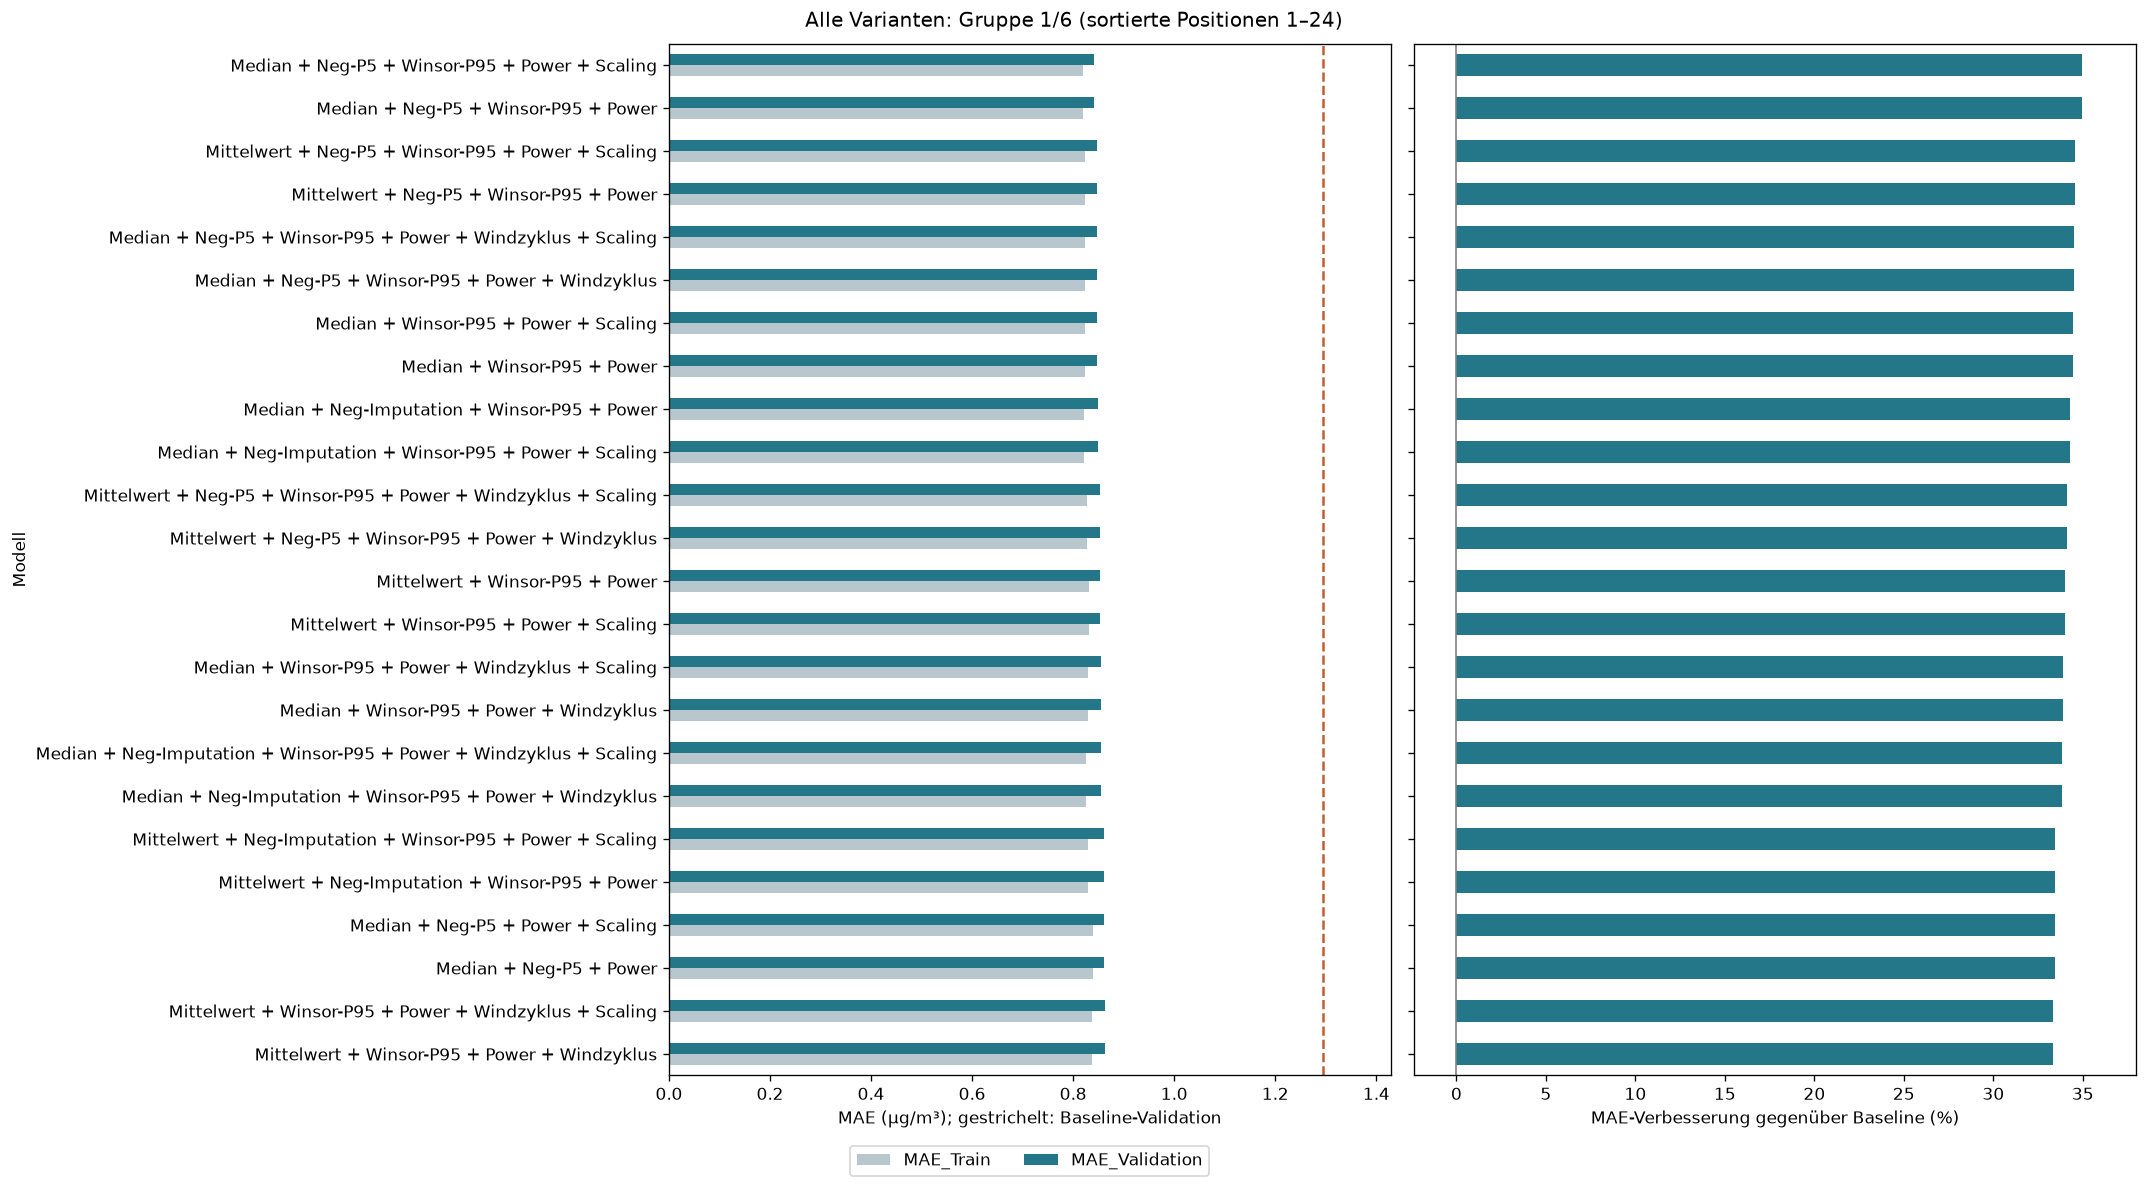

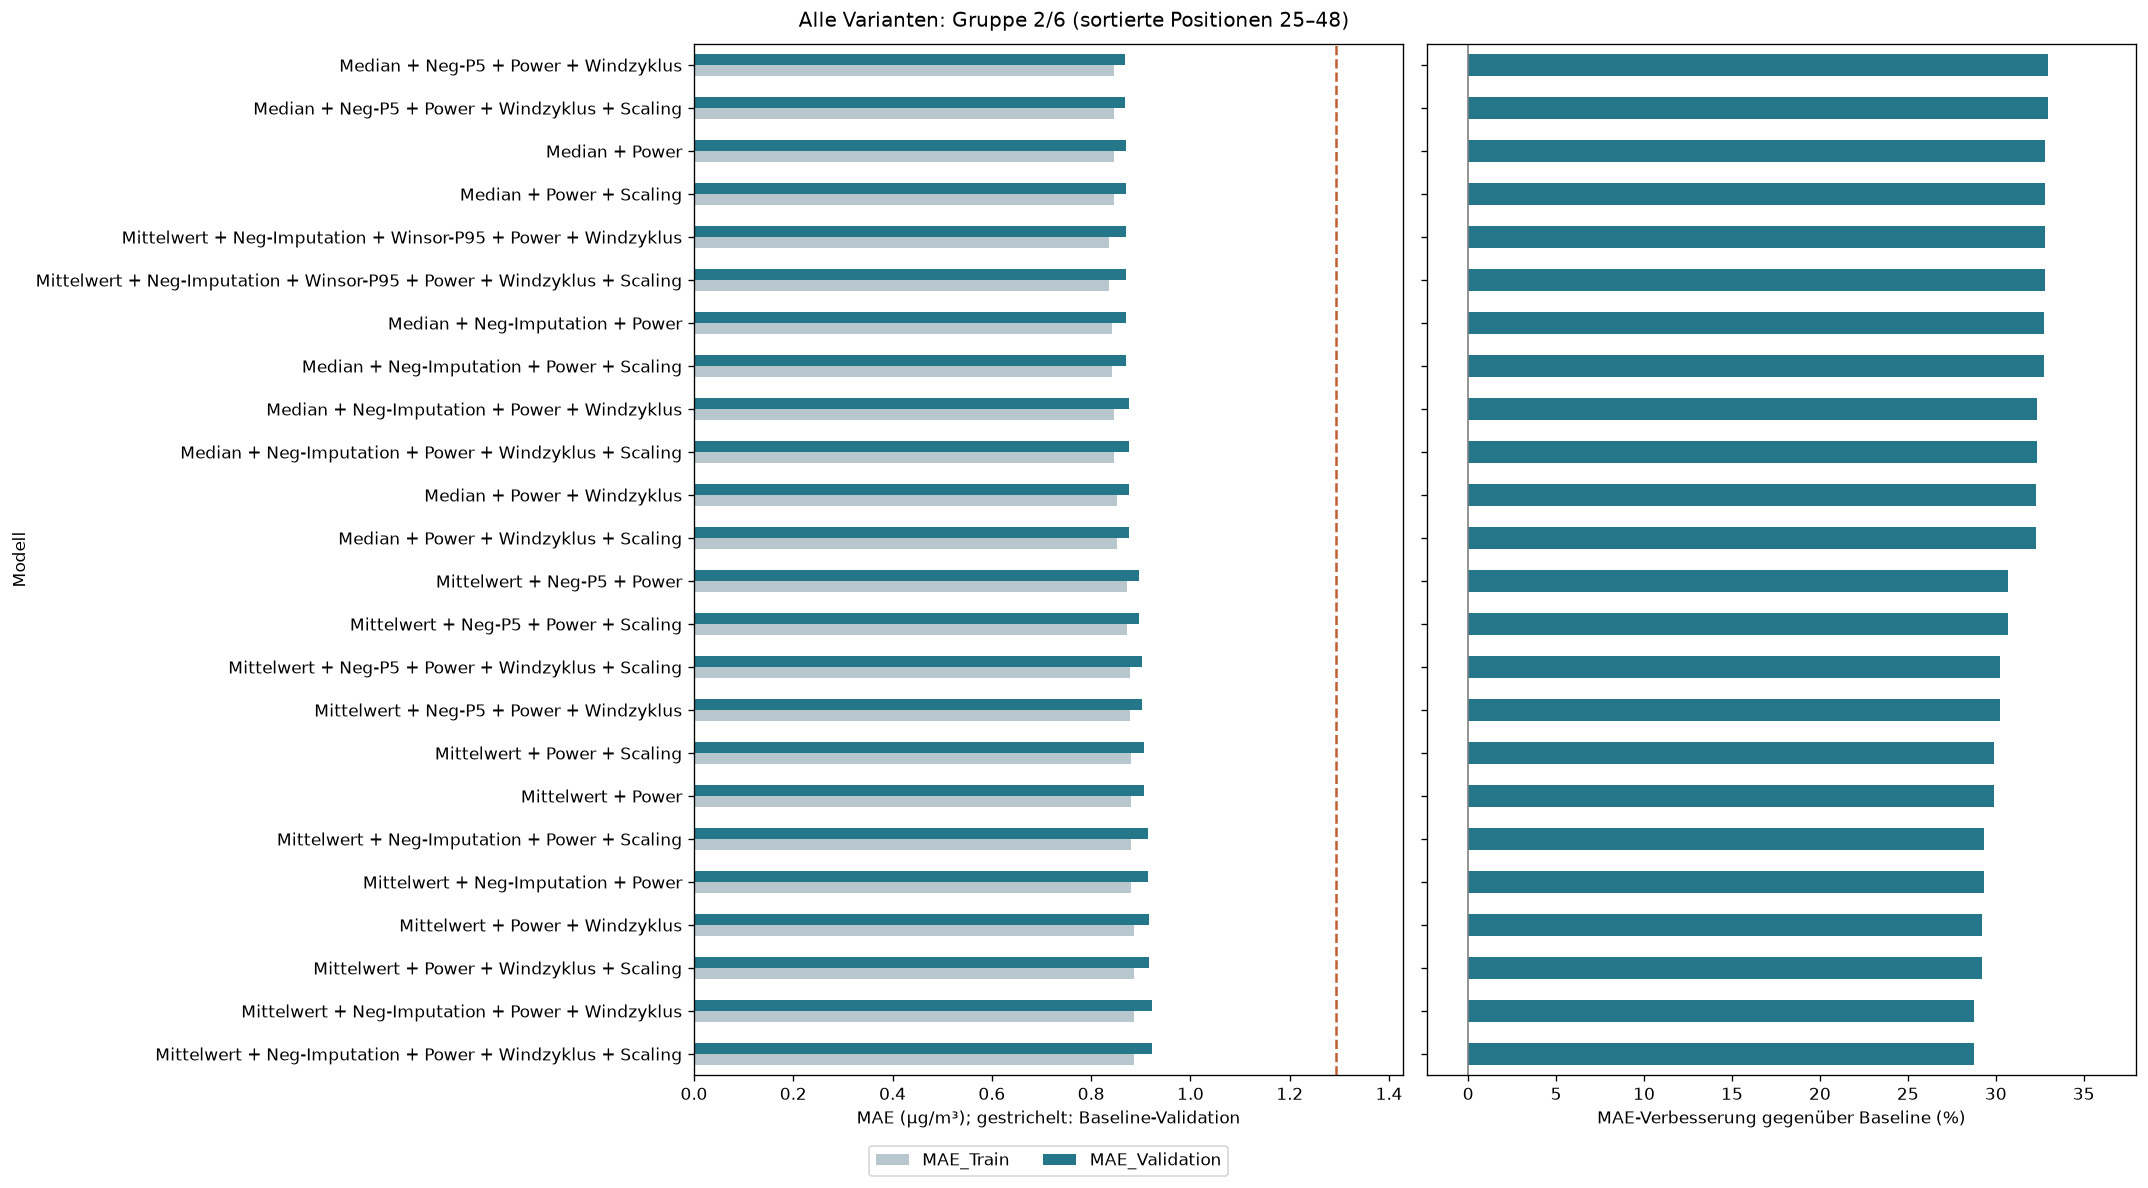

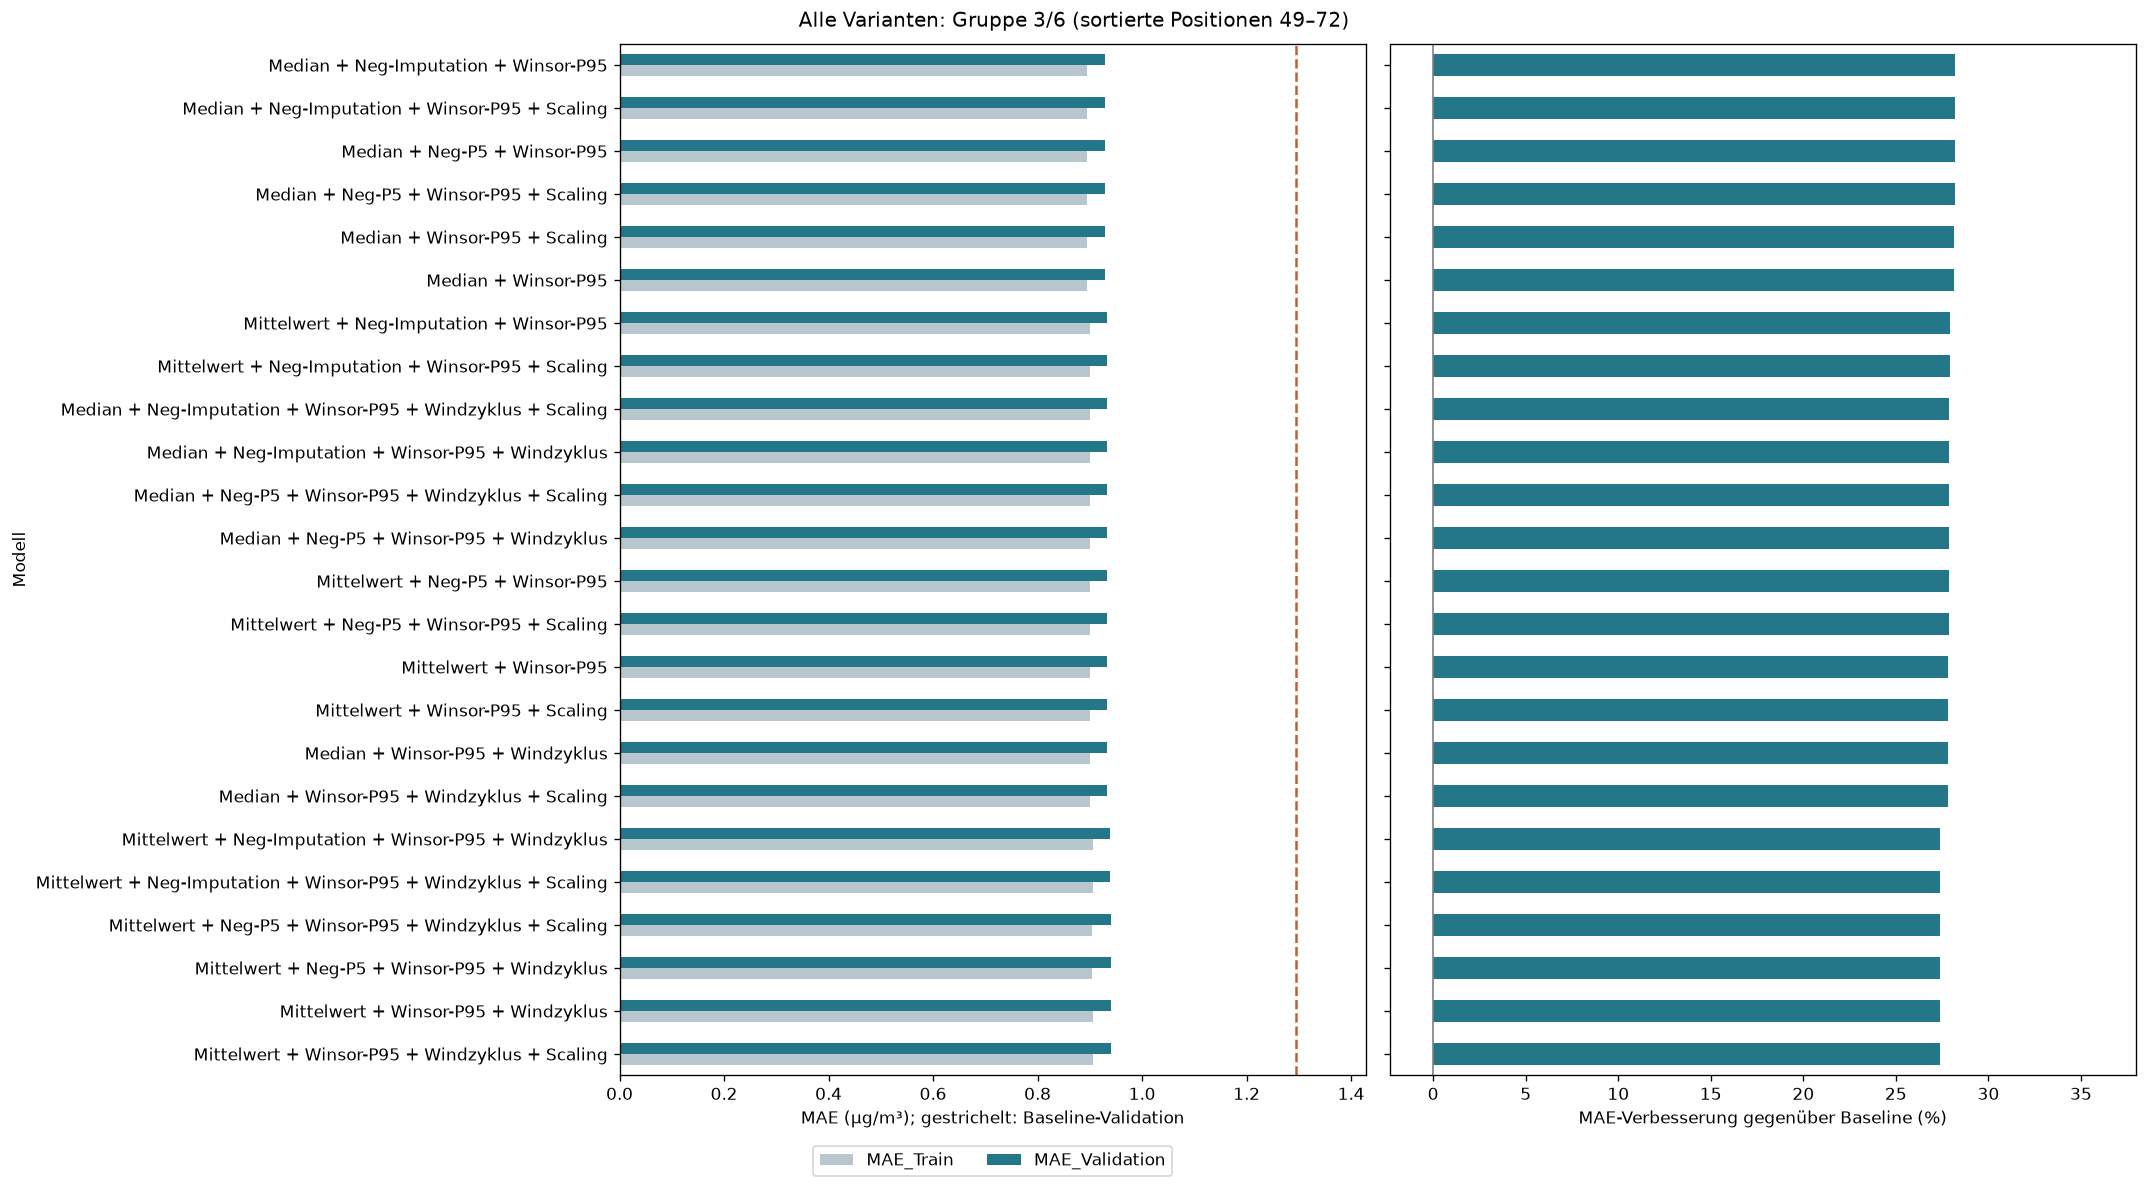

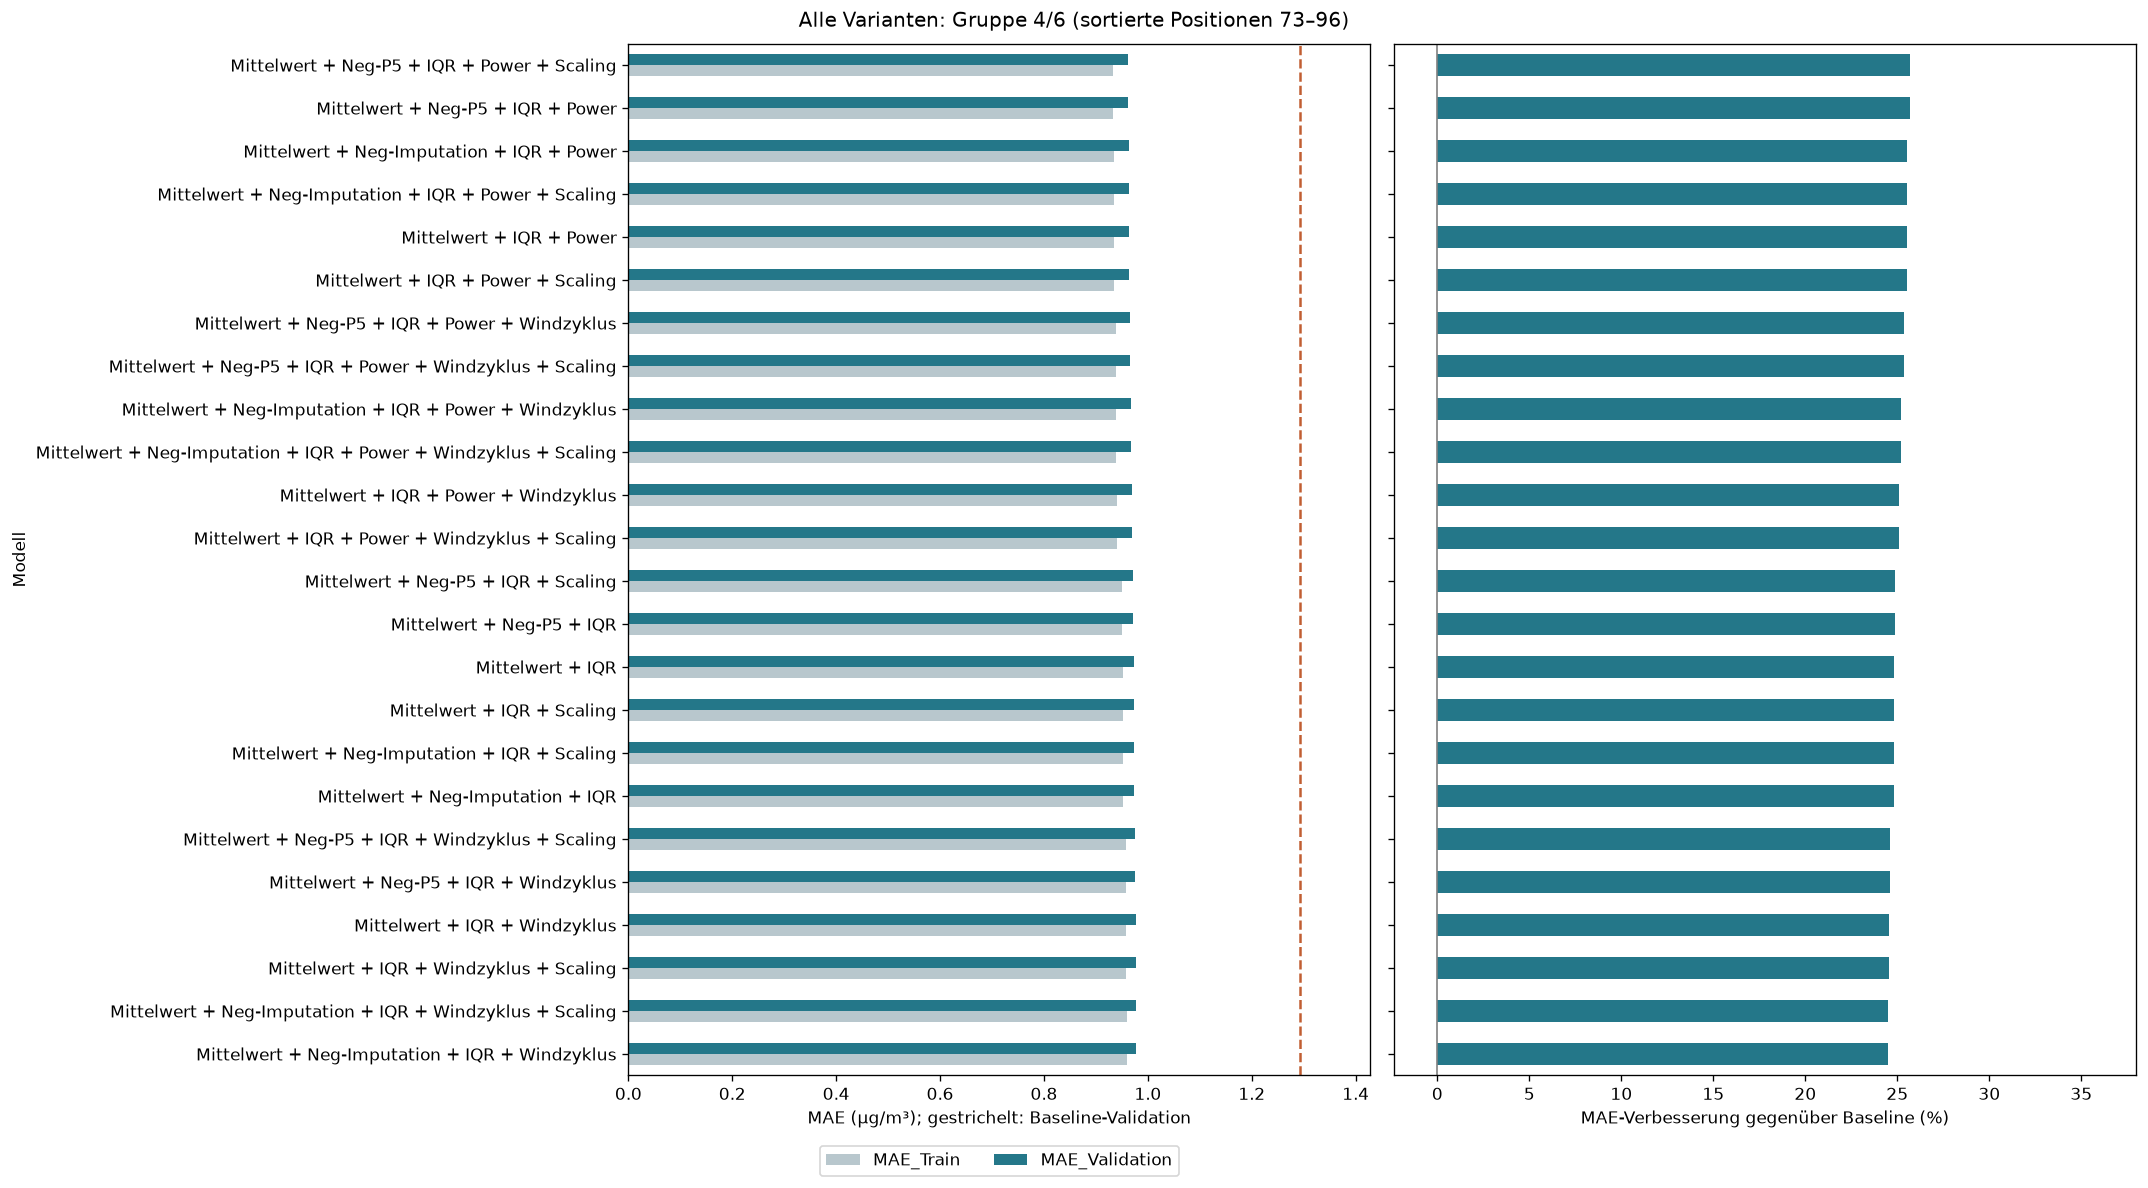

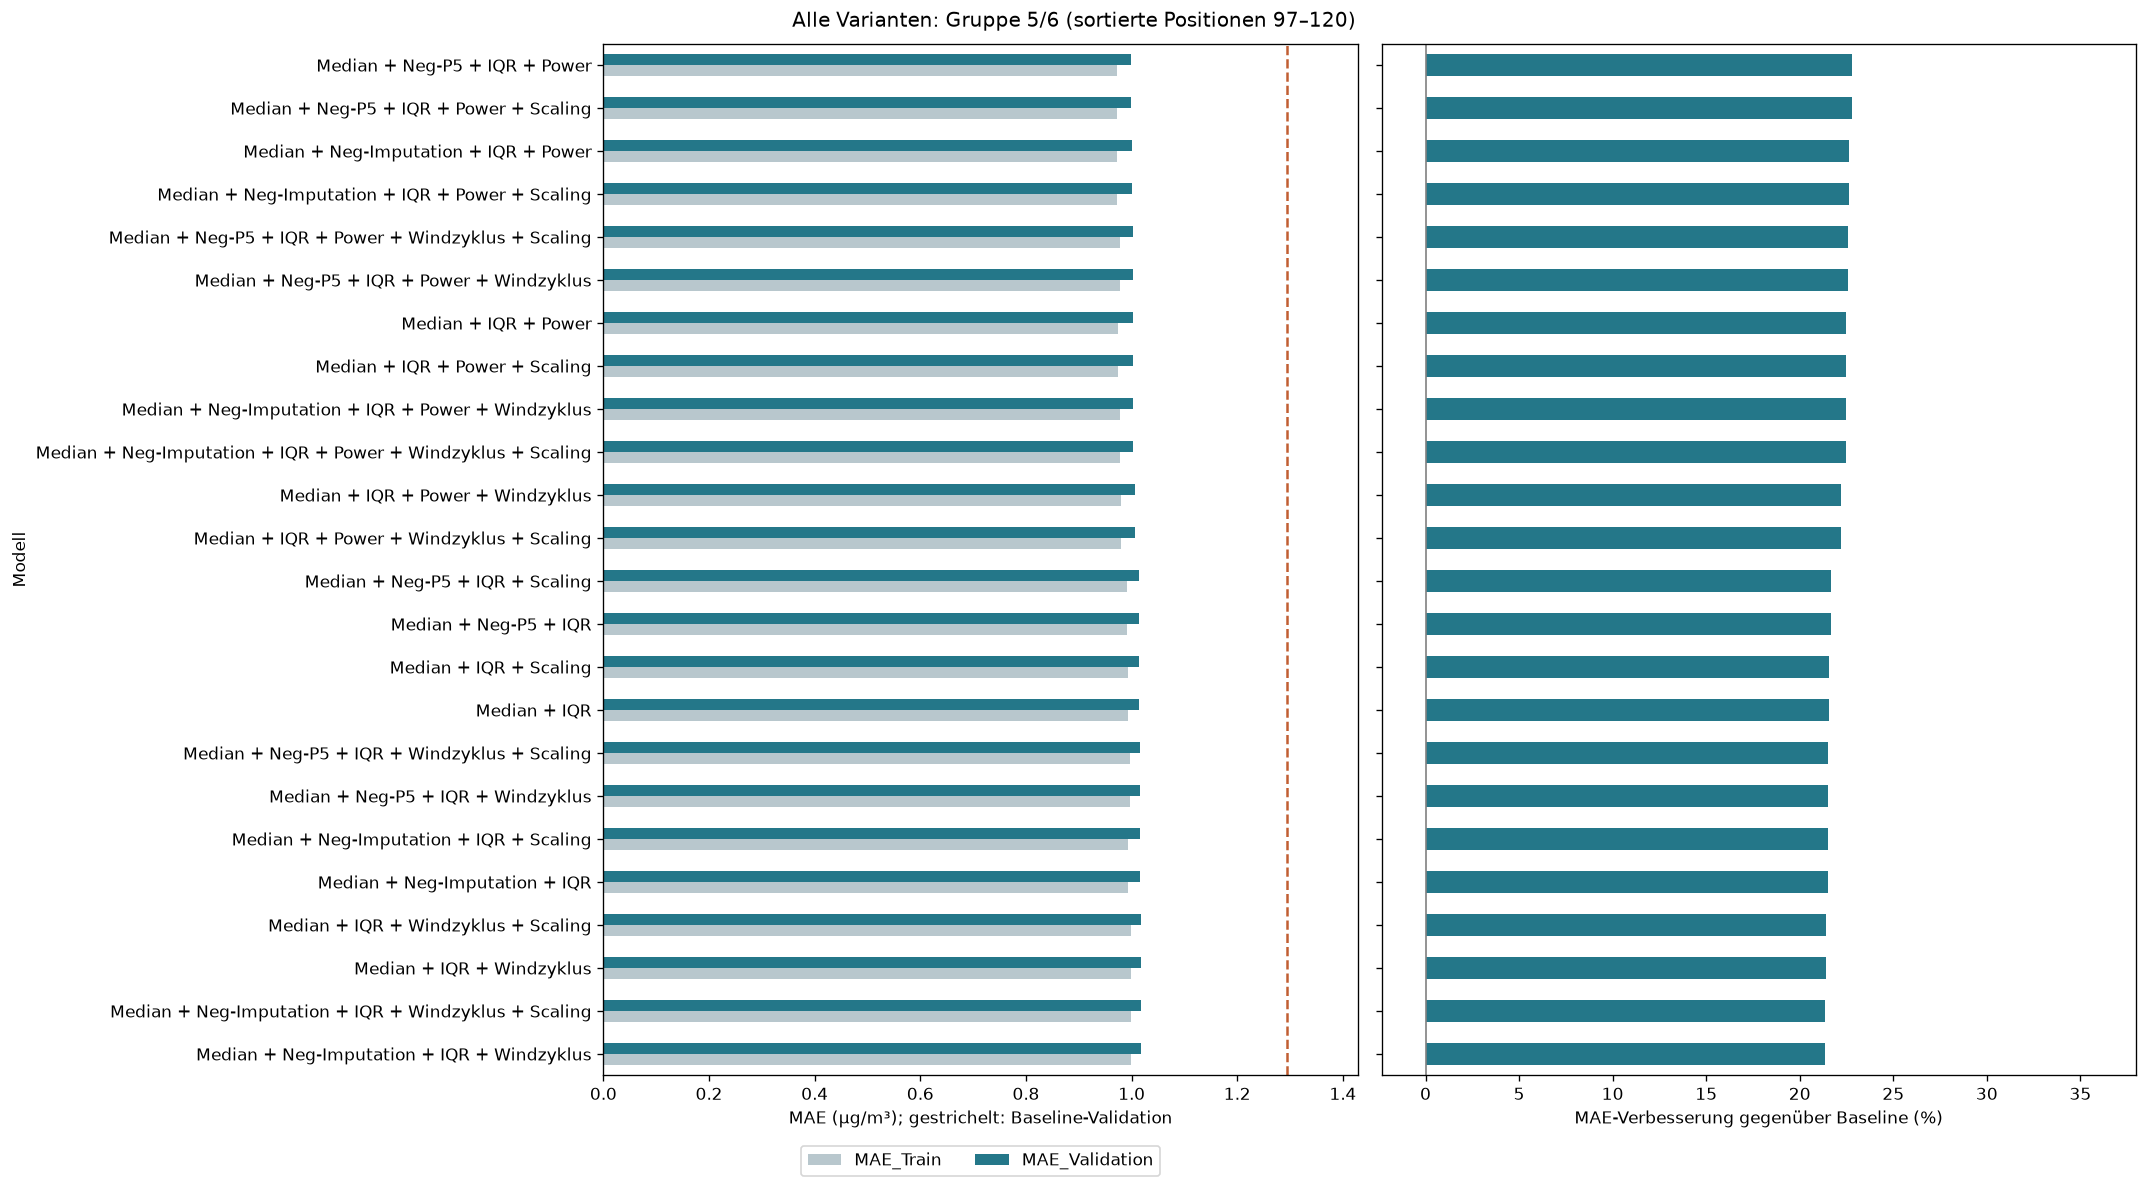

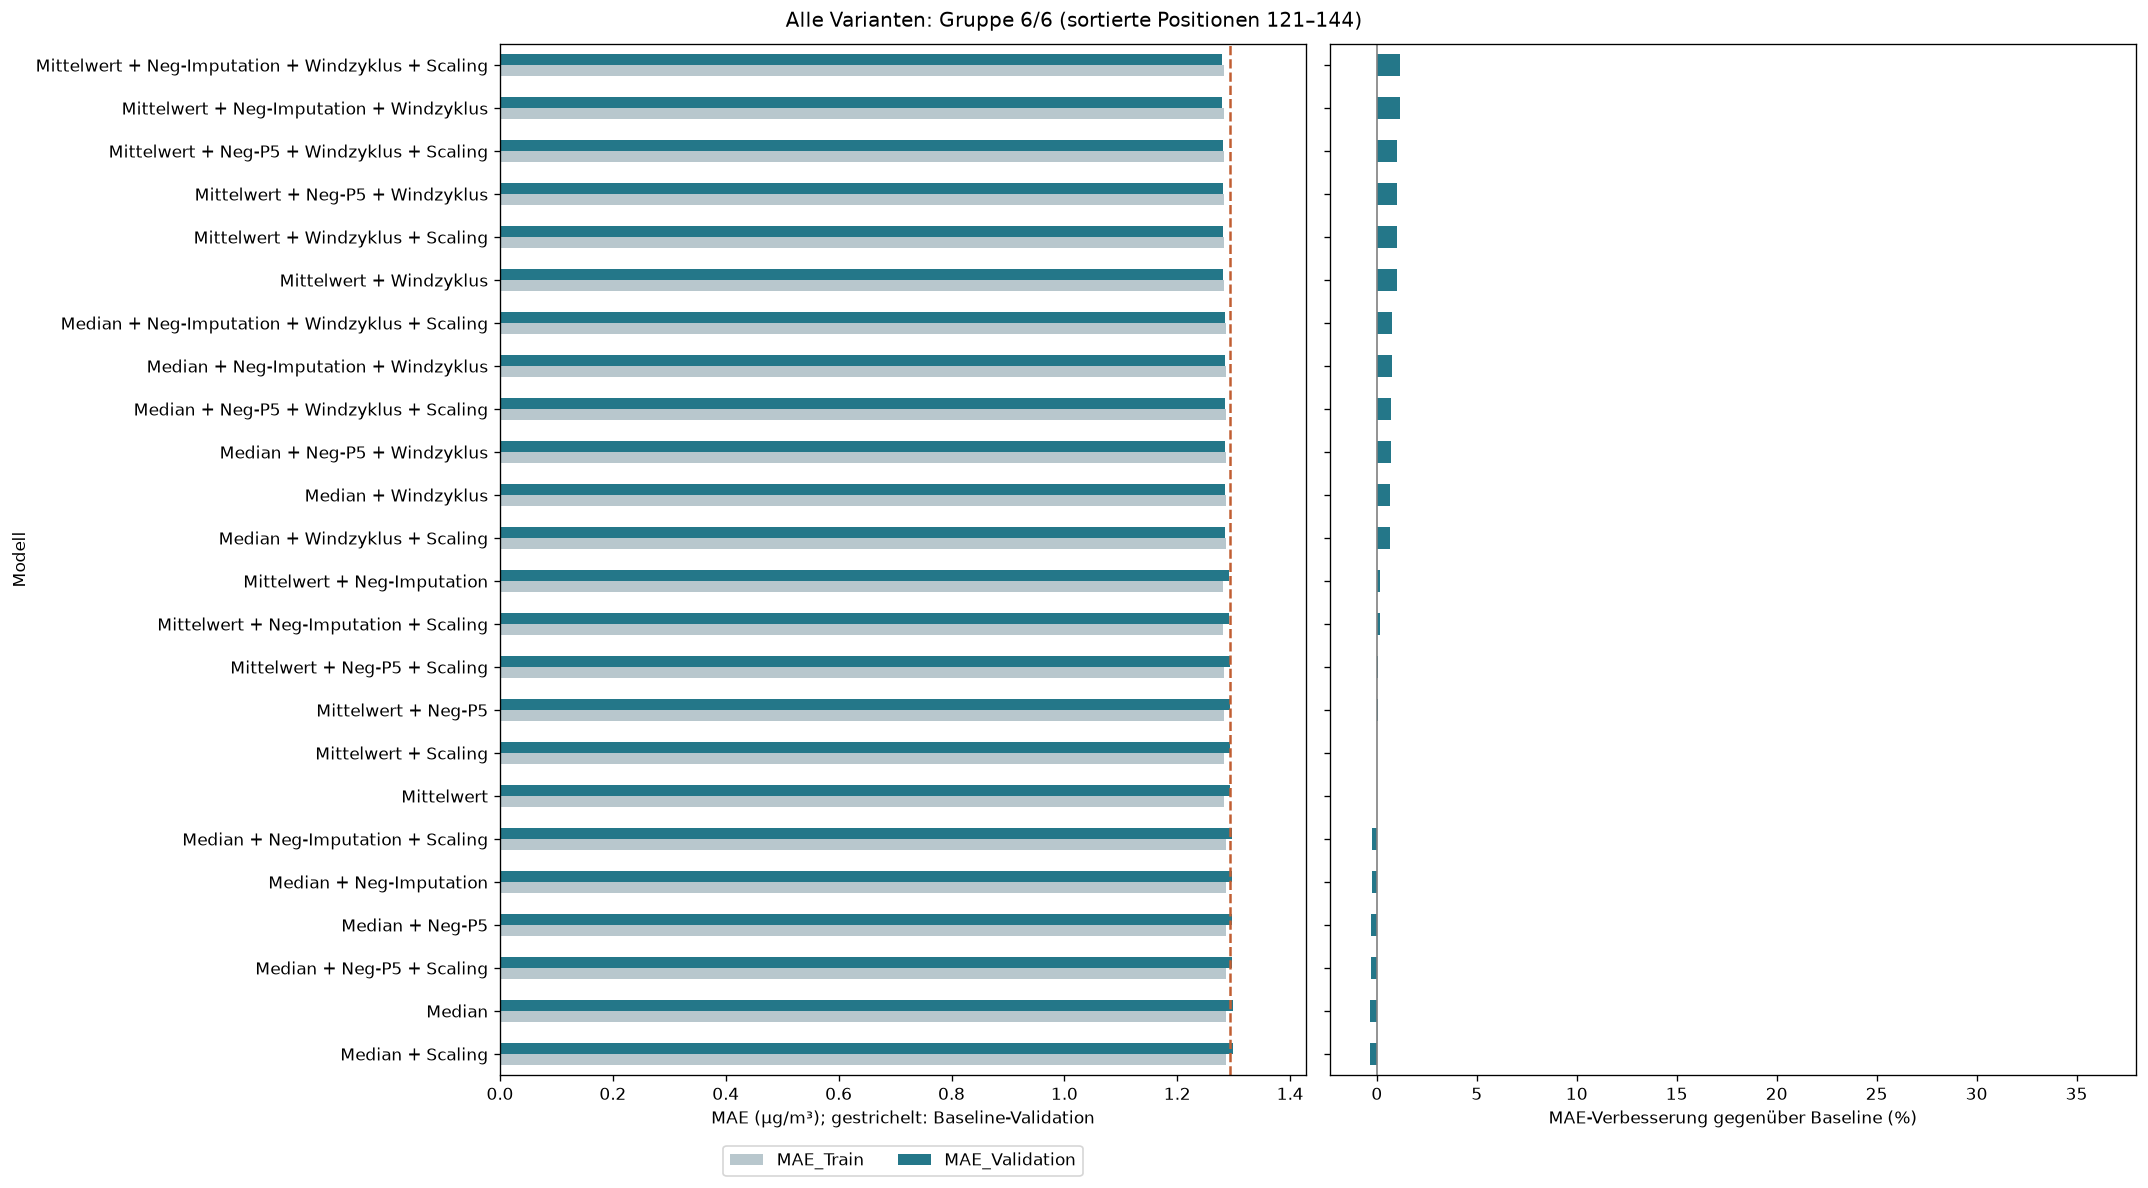

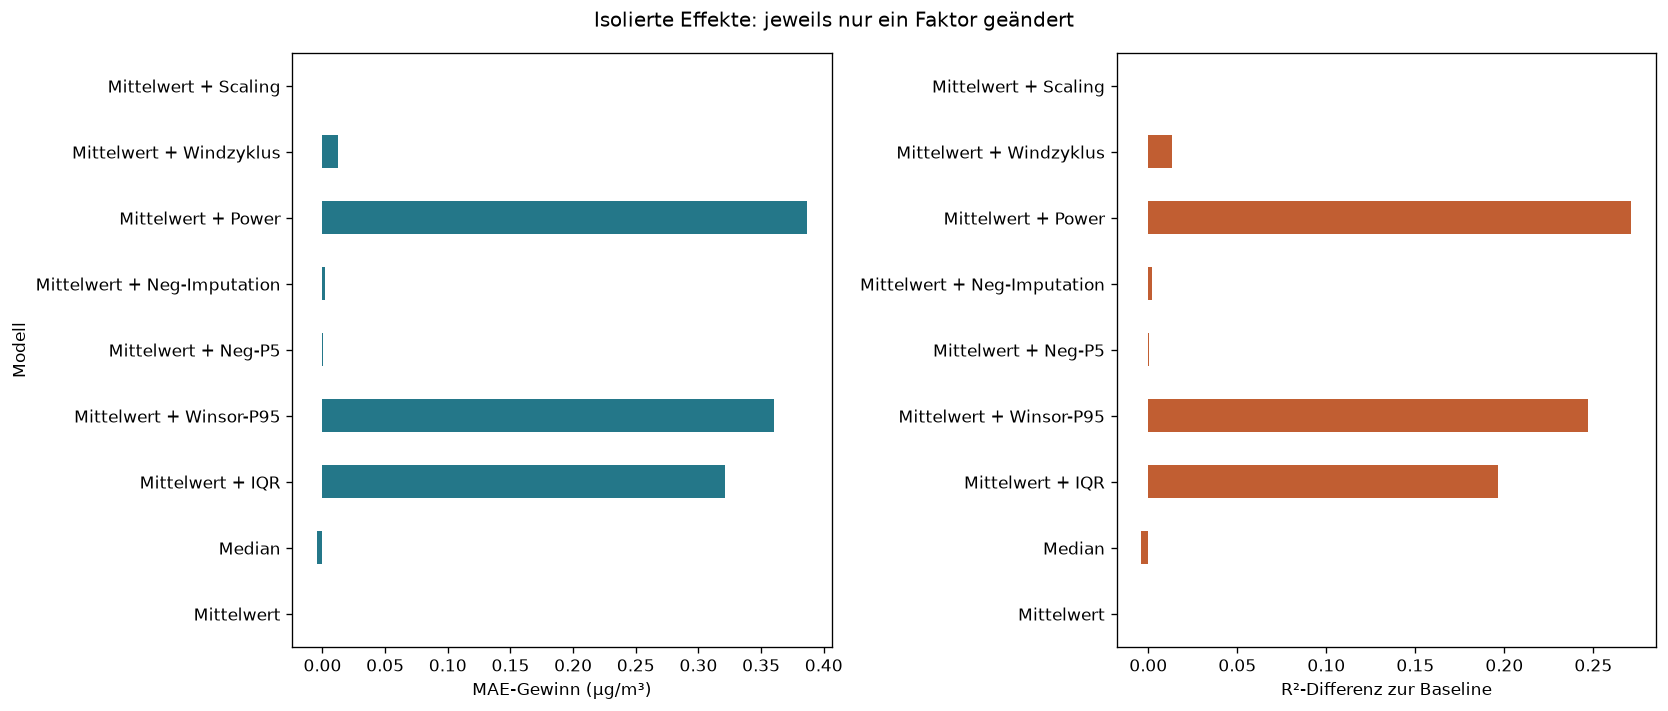

In [13]:
mae_limit = max(results['MAE_Train'].max(), results['MAE_Validation'].max()) * 1.1
gain_limits = (min(0, results['MAE_Gewinn_pct'].min()) - 2, results['MAE_Gewinn_pct'].max() + 3)
for group in range(6):
    plot_data = results.iloc[group*24:(group+1)*24].iloc[::-1].set_index('Modell')
    fig, axes = plt.subplots(1, 2, figsize=(18, 10), sharey=True)
    plot_data[['MAE_Train','MAE_Validation']].plot.barh(ax=axes[0], color=['#b8c7cd','#247789'])
    axes[0].axvline(baseline_result['MAE_Validation'], color='#c15e32', linestyle='--')
    axes[0].set_xlim(0,mae_limit)
    axes[0].set_xlabel('MAE (µg/m³); gestrichelt: Baseline-Validation')
    axes[0].legend(loc='upper center', bbox_to_anchor=(0.5,-0.06), ncol=2)
    plot_data['MAE_Gewinn_pct'].plot.barh(ax=axes[1], color='#247789')
    axes[1].axvline(0, color='grey', linewidth=1)
    axes[1].set_xlim(*gain_limits)
    axes[1].set_xlabel('MAE-Verbesserung gegenüber Baseline (%)')
    axes[1].set_ylabel('')
    fig.suptitle(f'Alle Varianten: Gruppe {group+1}/6 (sortierte Positionen {group*24+1}–{(group+1)*24})')
    fig.tight_layout()
    fig.savefig(FIGURES / f'all_variants_mae_{group+1}.png', bbox_inches='tight')
    plt.show()
fig, axes = plt.subplots(1,2,figsize=(14,6))
single_results.set_index('Modell')['MAE_Gewinn_abs'].plot.barh(ax=axes[0],color='#247789')
single_results.set_index('Modell')['R2_Delta'].plot.barh(ax=axes[1],color='#c15e32')
axes[0].set_xlabel('MAE-Gewinn (µg/m³)'); axes[1].set_xlabel('R²-Differenz zur Baseline')
axes[1].set_ylabel('')
fig.suptitle('Isolierte Effekte: jeweils nur ein Faktor geändert')
fig.tight_layout(); fig.savefig(FIGURES / 'single_step_deltas.png',bbox_inches='tight')
plt.show()

## 14. Kombinationen des neuen Tipps und Scaling
Die sechs Kombinationen aus Winsorisierung an/aus und Negativwertbehandlung keine/P5/Imputation werden zusätzlich bei ansonsten unveränderter Baseline zusammengefasst. Der zusätzliche Kombinationseffekt ist der gemeinsame Gewinn minus die Summe der Einzelgewinne; er ist eine deskriptive Interaktion auf diesem Split, kein Kausalnachweis.

Bei unregularisierter linearer Regression mit Intercept kann eine invertierbare affine Skalierung durch andere Koeffizienten ausgeglichen werden. Deshalb werden alle 72 Scaling-Paare direkt verglichen.

In [14]:
lookup = results.set_index('Modell')
base_mae = baseline_result['MAE_Validation']
combo_rows = []
for outliers in ['none', 'winsor95']:
    for negative in ['none','p05','impute']:
        config = dict(baseline_config, outliers=outliers, negative=negative)
        row = lookup.loc[config_name(config)]
        combo_rows.append({'Modell': row.name, 'MAE': row['MAE_Validation'],
            'R2': row['R2_Validation'], 'MAE_Gewinn': base_mae-row['MAE_Validation']})
combination_results = pd.DataFrame(combo_rows)
display(combination_results.round(6))
combination_results.to_csv(RESULTS / 'combination_effect.csv',index=False)
interaction_rows = []
for negative in ['p05','impute']:
    win = lookup.loc[config_name(dict(baseline_config,outliers='winsor95')),'MAE_Gewinn_abs']
    neg = lookup.loc[config_name(dict(baseline_config,negative=negative)),'MAE_Gewinn_abs']
    both = lookup.loc[config_name(dict(baseline_config,outliers='winsor95',negative=negative)),'MAE_Gewinn_abs']
    interaction_rows.append({'Negative':negative, 'Gewinn_Winsor':win, 'Gewinn_Negative':neg,
        'Gewinn_gemeinsam':both, 'Summe_einzeln':win+neg, 'Interaktion':both-win-neg})
interaction = pd.DataFrame(interaction_rows)
display(interaction.round(6))
interaction.to_csv(RESULTS / 'combination_interactions.csv',index=False)
scaling_pairs = []
for name, (state, model) in artifacts.items():
    if not state['config']['scaling']:
        scaled_name = config_name(dict(state['config'], scaling=True))
        scaled_state, scaled_model = artifacts[scaled_name]
        prediction = model.predict(apply_preparation(validation,state))
        scaled_prediction = scaled_model.predict(apply_preparation(validation,scaled_state))
        scaling_pairs.append({'Modell_ohne_Scaling':name,
            'MAE_Differenz_mit_minus_ohne':lookup.loc[scaled_name,'MAE_Validation']-lookup.loc[name,'MAE_Validation'],
            'max_prediction_difference':np.max(np.abs(scaled_prediction-prediction))})
scaling_comparison = pd.DataFrame(scaling_pairs)
assert len(scaling_comparison) == 72
scaling_comparison.to_csv(RESULTS / 'scaling_pairs.csv',index=False)
display(scaling_comparison.describe())

,Modell,MAE,R2,MAE_Gewinn
0,Mittelwert,1.293881,0.411688,0.000000
1,Mittelwert + Neg-P5,1.293236,0.412166,0.000645
2,Mittelwert + Neg-Imputation,1.291805,0.413998,0.002076
3,Mittelwert + Winsor-P95,0.933646,0.658922,0.360235
4,Mittelwert + Neg-P5 + Winsor-P95,0.933383,0.659087,0.360498
5,Mittelwert + Neg-Imputation + Winsor-P95,0.932337,0.659681,0.361544


,Negative,Gewinn_Winsor,Gewinn_Negative,Gewinn_gemeinsam,Summe_einzeln,Interaktion
0,p05,0.360235,0.000645,0.360498,0.360880,-0.000382
1,impute,0.360235,0.002076,0.361544,0.362311,-0.000767


,MAE_Differenz_mit_minus_ohne,max_prediction_difference
count,7.200000e+01,7.200000e+01
mean,1.541976e-17,1.370416e-13
std,2.383299e-15,1.206351e-13
min,-7.438494e-15,3.197442e-14
25%,-1.332268e-15,6.561418e-14
50%,-2.775558e-16,9.370282e-14
75%,1.332268e-15,1.503242e-13
max,5.995204e-15,6.039613e-13


## 15. Auswahl vor erneutem Testzugriff
Minimum Validation-MAE; Gleichstandstoleranz 10⁻⁸, dann weniger optionale Schritte. Alle 144 Varianten sind Kandidaten, einschließlich IQR und unveränderter negativer Werte als Kontrollvarianten. Die Empfehlung eines Verfahrens bedeutet nicht automatisch, dass es in diesem Vergleich gewinnen muss. Kein Refit auf Validation.

**Ausgewählt: Median + Neg-P5 + Winsor-P95 + Power.** Validation-MAE: **0.8414 µg/m³**; R²: **0.7282**; MAE-Verbesserung: **34.97%**. Training-MAE: 0.8189; Validation–Training-Abstand: 0.0225.

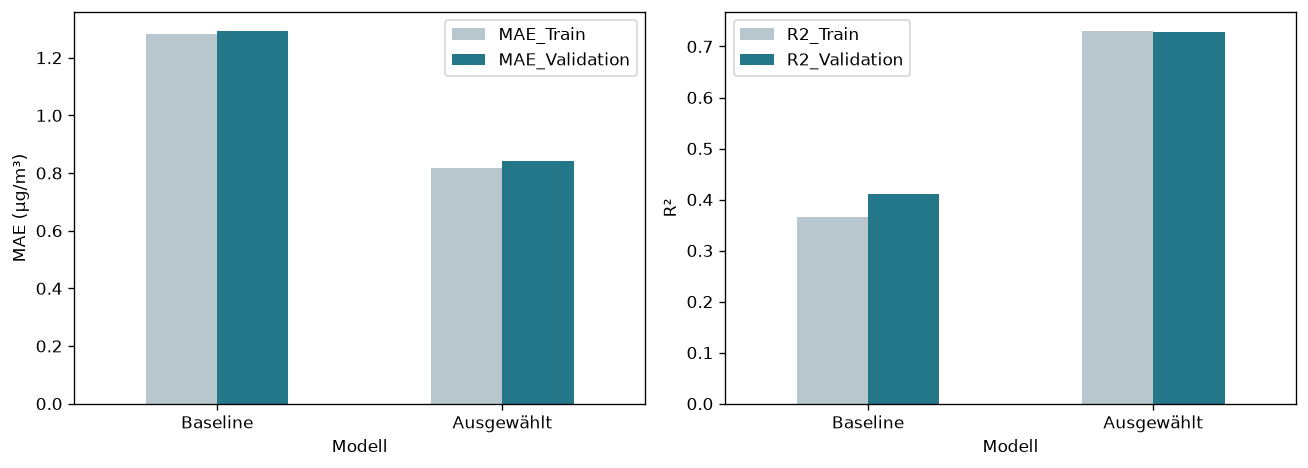

In [15]:
candidates = results.loc[results['MAE_Validation'] <= results['MAE_Validation'].min() + 1e-8]
best = candidates.sort_values(['n_optional','Modell']).iloc[0]
best_name = best['Modell']
best_state, best_model = artifacts[best_name]
selection = {'model': best_name, 'config': best_state['config'],
             'validation_mae': float(best['MAE_Validation']), 'validation_r2': float(best['R2_Validation']),
             'rule': 'Minimum Validation-MAE; Toleranz 1e-8, dann weniger optionale Schritte; kein Testzugriff',
             'refit_on_train_plus_validation': False}
(RESULTS / 'selected_model.json').write_text(json.dumps(selection, indent=2, ensure_ascii=False), encoding='utf-8')
display(Markdown(f"**Ausgewählt: {best_name}.** Validation-MAE: **{best['MAE_Validation']:.4f} µg/m³**; "
    f"R²: **{best['R2_Validation']:.4f}**; MAE-Verbesserung: **{best['MAE_Gewinn_pct']:.2f}%**. "
    f"Training-MAE: {best['MAE_Train']:.4f}; Validation–Training-Abstand: {best['MAE_Gap']:.4f}."))
# Kompakte Bezeichnungen, damit auch lange Kombinationsnamen lesbar bleiben.
selected_comparison = pd.DataFrame([
    {'Modell':'Baseline', **{k:baseline_result[k] for k in ['MAE_Train','MAE_Validation','R2_Train','R2_Validation']}},
    {'Modell':'Ausgewählt', **{k:best[k] for k in ['MAE_Train','MAE_Validation','R2_Train','R2_Validation']}}
]).set_index('Modell')
fig, axes = plt.subplots(1,2,figsize=(11,4))
selected_comparison[['MAE_Train','MAE_Validation']].plot.bar(ax=axes[0],rot=0,color=['#b8c7cd','#247789'])
selected_comparison[['R2_Train','R2_Validation']].plot.bar(ax=axes[1],rot=0,color=['#b8c7cd','#247789'])
axes[0].set_ylabel('MAE (µg/m³)'); axes[1].set_ylabel('R²')
fig.tight_layout(); fig.savefig(FIGURES / 'overfitting_comparison.png',bbox_inches='tight')
plt.show()

## 16. Eingriffe und Schutz vor Datenleckage prüfen
Der Audit trennt negative Werte, PM2.5-Kappungen und zusätzliche NaNs. Prüfungen stellen sicher: Quantile stammen aus Training, P5-Ersetzungen sind nichtnegativ, Winsorisierung verändert keine gültigen kleinen Werte, die Verarbeitung einer Zeile hängt nicht von anderen Validierungszeilen ab. Keine dieser Prüfungen wählt ein Modell anhand des Tests.

In [16]:
audit_rows = []
for name in ['train','validation']:
    frame = training if name == 'train' else validation
    X = represent_features(frame,best_state['origin'],best_state['config']['cyclic'])
    corrected = apply_negative_values(X,best_state['config']['negative'],best_state['negative_bounds'])
    treated = apply_value_treatments(X,best_state)
    for col in best_state['numeric']:
        audit_rows.append({'split':name,'feature':col,'missing_before':int(X[col].isna().sum()),
            'negative_before':int((X[col]<0).sum()) if col in NEGATIVE_FEATURES else 0,
            'missing_after_treatment':int(treated[col].isna().sum()),
            'p95_caps':int((corrected[col]>best_state['winsor95']).sum()) if col=='pm25_lowcost' and best_state['config']['outliers']=='winsor95' else 0})
preparation_audit = pd.DataFrame(audit_rows)
display(preparation_audit)
preparation_audit.to_csv(RESULTS / 'selected_preparation_audit.csv',index=False)
# Alle relevanten Quantilparameter, auch wenn eine Regel nicht ausgewählt wurde.
pd.DataFrame({'p05_nonnegative':best_state['negative_bounds']}).to_csv(RESULTS / 'training_p05_bounds.csv')
pd.DataFrame([{'feature':'pm25_lowcost','p95':best_state['winsor95']}]).to_csv(RESULTS / 'training_p95_bound.csv',index=False)
pd.DataFrame({'feature':best_state['numeric'],'value':best_state['imputer'].statistics_}).to_csv(RESULTS / 'selected_imputation_values.csv',index=False)
if best_state['bounds'] is not None:
    best_state['bounds'].to_csv(RESULTS / 'selected_iqr_bounds.csv')
if best_state['power'] is not None:
    pd.DataFrame({'feature':POWER_FEATURES,'lambda':best_state['power'].lambdas_}).to_csv(RESULTS / 'selected_power_parameters.csv',index=False)
# Prüfe beide neuen Methoden unabhängig davon, ob sie gewinnen.
probe_state = fit_preparation(training,dict(baseline_config,outliers='winsor95',negative='p05'))
assert np.isclose(probe_state['winsor95'],training['pm25_lowcost'].quantile(.95))
pd.testing.assert_series_equal(probe_state['negative_bounds'],fit_negative_bounds(training))
raw_X = represent_features(validation,probe_state['origin'])
changed_X = apply_value_treatments(raw_X,probe_state)
low = raw_X['pm25_lowcost'].between(0,probe_state['winsor95'])
pd.testing.assert_series_equal(raw_X.loc[low,'pm25_lowcost'],changed_X.loc[low,'pm25_lowcost'])
assert changed_X['pm25_lowcost'].max() <= probe_state['winsor95']
assert not (changed_X[NEGATIVE_FEATURES]<0).any().any()
for method in ['p05','impute']:
    transformed = apply_negative_values(raw_X,method,probe_state['negative_bounds'])
    mask = raw_X['no'] < 0
    if method=='p05': assert transformed.loc[mask,'no'].eq(probe_state['negative_bounds']['no']).all()
    else: assert transformed.loc[mask,'no'].isna().all()
for state in [best_state,probe_state]:
    together=apply_preparation(validation,state)
    separately=apply_preparation(validation.iloc[[0]],state)
    np.testing.assert_allclose(together.iloc[[0]],separately,rtol=1e-12,atol=1e-12)
print('Quantil-, Negativwert-, Winsorisierungs- und Batch-Prüfungen bestanden.')

,split,feature,missing_before,negative_before,missing_after_treatment,p95_caps
0,train,pm25_lowcost,263,0,263,124
1,train,no,13,376,13,0
2,train,no2,13,0,13,0
3,train,o3,586,0,586,0
4,train,co2,756,0,756,0
5,train,black_carbon,0,0,0,0
6,train,ufp,458,0,458,0
7,train,temperature,312,0,312,0
8,train,relative_humidity,312,0,312,0
9,train,pressure,312,0,312,0


Quantil-, Negativwert-, Winsorisierungs- und Batch-Prüfungen bestanden.


## 17. Abschließende Bewertung auf dem offiziellen Test
Erst nach der hier gespeicherten Auswahl wird die Testdatei in **dieser Ausführung** geladen. Sie ist aus früheren Versionen bekannt und darf deshalb nicht als neuer unberührter Holdout bezeichnet werden. Es erfolgt keine weitere Auswahl oder Parameteranpassung anhand dieses Ergebnisses.

Unbekannte `year_month`-Kategorien werden gemäß Lab mit `handle_unknown='ignore'` als Nullen kodiert, genau wie die Referenzkategorie. Das ist eine Grenze der zeitlichen Übertragbarkeit. MAE/R² werden nur für vorhandene Labels berechnet; alle 1.464 Testzeilen erhalten Vorhersagen.

In [17]:
test = pd.read_csv(DATA / 'pm25_test.csv')
assert test.shape == (1464, 17)
assert list(test.columns) == list(original_train.columns)
test_labels_before = test[TARGET].copy()
test_index_before = test.index.copy()
X_train_final = apply_preparation(training, best_state)
X_val_final = apply_preparation(validation, best_state)
X_test_final = apply_preparation(test, best_state)
assert X_train_final.columns.equals(X_val_final.columns)
assert X_train_final.columns.equals(X_test_final.columns)
test_prediction = best_model.predict(X_test_final)
test_result = metrics(test[TARGET], test_prediction)
test_results = pd.DataFrame([{'Modell': best_name, **test_result}])
display(test_results)
test_results.to_csv(RESULTS / 'final_test_metrics.csv', index=False)
known_months = set(best_state['encoder'].categories_[0])
unknown_months = sorted(set(test['year_month']) - known_months)
print('Testmonate ohne Trainingskategorie:', unknown_months)
print('Nicht bewertbare Testlabels:', int(test[TARGET].isna().sum()))
print('Testlabels und Zeilen bleiben vollständig erhalten.')

/Users/kevin/Documents/ChatGPT/Data Science Projekt/.venv/lib/python3.12/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


,Modell,MAE,R2,n_rows,n_scored
0,Median + Neg-P5 + Winsor-P95 + Power,2.193486,0.038223,1464,1419


Testmonate ohne Trainingskategorie: ['2024-11', '2024-12']
Nicht bewertbare Testlabels: 45
Testlabels und Zeilen bleiben vollständig erhalten.


## 18. CSV-Export für Task 3 und Integritätskontrollen
Die Feature-Spalten aller drei Dateien sind identisch. Das Label bleibt in ursprünglichen Einheiten. Die ursprüngliche CSV-Zeilennummer (0-basiert, ohne Kopfzeile) liegt in separaten Manifesten, damit sie nicht versehentlich als Feature genutzt wird.

Die Trainingsdatei enthält nur tatsächlich für den Fit verwendete Zeilen. Alle entfernten Trainingszeilen sind protokolliert. **Validation und Test werden vollständig exportiert**, auch wenn Labels fehlen. Task 3 muss für Metriken dieselbe Labelmaske verwenden. Keine neue Skalierung oder Imputation auf Validation/Test fitten.

In [18]:
exports = {}
for split_name, raw, prepared in [('train',training,X_train_final), ('validation',validation,X_val_final), ('test',test,X_test_final)]:
    exported = prepared.copy()
    exported[TARGET] = raw[TARGET]
    assert len(exported) == len(raw)
    pd.testing.assert_series_equal(exported[TARGET], raw[TARGET])
    path = RESULTS / f'pm25_preprocessed_{split_name}.csv'
    exported.to_csv(path, index=False)
    reread = pd.read_csv(path)
    assert len(reread) == len(raw)
    np.testing.assert_allclose(reread[TARGET], raw[TARGET], equal_nan=True)
    assert np.isfinite(reread.drop(columns=TARGET).to_numpy()).all()
    pd.DataFrame({'source_file': 'pm25_test.csv' if split_name == 'test' else 'pm25_train.csv',
        'source_row': raw.index, 'timestamp': raw['timestamp'].to_numpy()}).to_csv(RESULTS / f'row_manifest_{split_name}.csv', index=False)
    exports[split_name] = exported
pd.testing.assert_series_equal(validation[TARGET], validation_labels_before)
pd.testing.assert_series_equal(test[TARGET], test_labels_before)
assert validation.index.equals(validation_index_before)
assert test.index.equals(test_index_before)
assert len(exports['validation']) == 682 and len(exports['test']) == 1464
assert exports['train'].columns.equals(exports['validation'].columns)
assert exports['train'].columns.equals(exports['test'].columns)
# Das exportierte Training reproduziert das ausgewählte Modell ohne weiteres Preprocessing.
roundtrip_model = LinearRegression().fit(pd.read_csv(RESULTS / 'pm25_preprocessed_train.csv').drop(columns=TARGET),
                                       pd.read_csv(RESULTS / 'pm25_preprocessed_train.csv')[TARGET])
np.testing.assert_allclose(roundtrip_model.predict(pd.read_csv(RESULTS / 'pm25_preprocessed_test.csv').drop(columns=TARGET)),
                           test_prediction, rtol=1e-7, atol=1e-7)
pd.DataFrame({'source_row': test.index, 'pm25_target': test[TARGET], 'prediction': test_prediction}).to_csv(RESULTS / 'test_predictions.csv', index=False)
print('Prüfungen bestanden: Zeilen, Labelwerte, Featurelayout, endliche Features und CSV-Roundtrip.')
display(pd.DataFrame([{'Datei': key, 'Zeilen': len(value), 'Features': value.shape[1]-1} for key,value in exports.items()]))

Prüfungen bestanden: Zeilen, Labelwerte, Featurelayout, endliche Features und CSV-Roundtrip.


,Datei,Zeilen,Features
0,train,2727,19
1,validation,682,19
2,test,1464,19


## 19. Learnings aus der tatsächlich ausgeführten Revision
Die folgenden Ergebnisse werden aus den Logs abgeleitet. Der Vergleich mit den früheren Task-2-Zahlen ist wegen des geänderten Splits nicht als Wirkung der Winsorisierung interpretierbar. Nur die Vergleiche innerhalb dieser Revision isolieren Maßnahmen.

In [19]:
best_single = single_results.sort_values('MAE_Validation').iloc[0]
win_row = lookup.loc['Mittelwert + Winsor-P95']
iqr_row = lookup.loc['Mittelwert + IQR']
negative_p5 = lookup.loc['Mittelwert + Neg-P5']
negative_imp = lookup.loc['Mittelwert + Neg-Imputation']
learnings = f"""# Ergebnisse der Revision mit Task 1

- Split exakt wie Task 1: {len(training)} Training / {len(validation)} Validation; 204 fehlende Labels vor dem Split ausgeschlossen.
- Baseline mit allen 16 Originalfeatures: Validation-MAE {base_mae:.4f} µg/m³; R² {baseline_result['R2_Validation']:.4f}.
- Winsor-P95 allein: MAE {win_row['MAE_Validation']:.4f}; Verbesserung {win_row['MAE_Gewinn_pct']:.2f}%.
- IQR allein als Vergleich: MAE {iqr_row['MAE_Validation']:.4f}; Verbesserung {iqr_row['MAE_Gewinn_pct']:.2f}%.
- Negative Werte → P5 allein: MAE {negative_p5['MAE_Validation']:.4f}; negative Werte → Imputation allein: {negative_imp['MAE_Validation']:.4f}.
- NO-P5 ungefiltert {quantile_audit.loc['no','p05_unfiltered']:.3f}; aus nichtnegativen Trainingswerten {quantile_audit.loc['no','p05_nonnegative']:.3f}. Ungefiltertes P5 würde den Fehler nicht beheben.
- 144 Konfigurationen geprüft. Ausgewählt: **{best_name}**. Validation-MAE {best['MAE_Validation']:.4f}; R² {best['R2_Validation']:.4f}.
- MAE-Gewinn zur selben Baseline: {best['MAE_Gewinn_abs']:.4f} µg/m³ bzw. {best['MAE_Gewinn_pct']:.2f}%; R²-Differenz {best['R2_Delta']:.4f}.
- Training-MAE {best['MAE_Train']:.4f}; Validation–Training-Abstand {best['MAE_Gap']:.4f}. Ein Abstand allein beweist kein Overfitting.
- 72 Scaling-Paare: maximale absolute MAE-Änderung {scaling_comparison['MAE_Differenz_mit_minus_ohne'].abs().max():.2e}; unregularisierte OLS ist gegenüber affiner Skalierung grundsätzlich invariant.
- Abschließender Test: MAE {test_result['MAE']:.4f} µg/m³; R² {test_result['R2']:.4f}; bewertet {test_result['n_scored']} von {test_result['n_rows']} Zeilen. 45 fehlende Labels bleiben fehlend, alle Zeilen bleiben exportiert.
- Export: {len(training)} / {len(validation)} / {len(test)} Zeilen; {X_train_final.shape[1]} Features und unverändertes Label.

## Interpretation und Grenzen

Die P95-Kappung erhält das Feature und seine üblichen Werte, begrenzt aber alle Messungen oberhalb des Trainings-P95. Das kann auch echte Belastungsspitzen betreffen. IQR-Imputation ist ein anders definierter Eingriff und kann entsprechend anders wirken. Die Kombinationstabellen zeigen, ob beide neuen Tipps zusammen mehr bringen als ihre isolierten Effekte.

Keine Feature Selection in Task 2. Derselbe Split wie Task 1 verbessert die Vergleichbarkeit des Projektablaufs, aber die Task-1-Baseline enthält nur ein Feature und ist nicht die Task-2-Baseline. Zufällige Mischung benachbarter Stunden sowie 144 Varianten auf derselben Validation können optimistische Gütewerte ergeben.

Der Test war bereits bekannt; diese Revision ist kein neuer unabhängiger Holdout-Versuch. Keine Modellauswahl anhand des Tests. Unbekannte Testmonate {unknown_months} werden über die OHE-Nullkodierung abgebildet. Bei negativem R² ist der quadratische Fehler größer als bei einer konstanten Vorhersage des Mittelwerts der bewerteten Labels. Änderungen gegenüber der alten Version sind wegen des neuen Splits nicht allein der Ausreißerbehandlung zurechenbar.
"""
display(Markdown(learnings))
(RESULTS / 'LEARNINGS.md').write_text(learnings,encoding='utf-8')
presentation_data = {'baseline':baseline_result,'best':best.to_dict(),'test':test_result,
    'single':single_results.to_dict(orient='records'),'combinations':combination_results.to_dict(orient='records'),
    'interaction':interaction.to_dict(orient='records'),'n_train':len(training),'n_validation':len(validation),
    'n_test':len(test),'n_features':X_train_final.shape[1],'unknown_months':unknown_months,
    'max_scaling_mae_difference':float(scaling_comparison['MAE_Differenz_mit_minus_ohne'].abs().max()),
    'pm25_p95':float(best_state['winsor95']),'no_p05':float(best_state['negative_bounds']['no']),
    'negative_no':int((training['no']<0).sum())}
(RESULTS / 'presentation_data.json').write_text(json.dumps(presentation_data,indent=2,ensure_ascii=False),encoding='utf-8')

# Ergebnisse der Revision mit Task 1

- Split exakt wie Task 1: 2727 Training / 682 Validation; 204 fehlende Labels vor dem Split ausgeschlossen.
- Baseline mit allen 16 Originalfeatures: Validation-MAE 1.2939 µg/m³; R² 0.4117.
- Winsor-P95 allein: MAE 0.9336; Verbesserung 27.84%.
- IQR allein als Vergleich: MAE 0.9727; Verbesserung 24.82%.
- Negative Werte → P5 allein: MAE 1.2932; negative Werte → Imputation allein: 1.2918.
- NO-P5 ungefiltert -0.600; aus nichtnegativen Trainingswerten 0.100. Ungefiltertes P5 würde den Fehler nicht beheben.
- 144 Konfigurationen geprüft. Ausgewählt: **Median + Neg-P5 + Winsor-P95 + Power**. Validation-MAE 0.8414; R² 0.7282.
- MAE-Gewinn zur selben Baseline: 0.4525 µg/m³ bzw. 34.97%; R²-Differenz 0.3165.
- Training-MAE 0.8189; Validation–Training-Abstand 0.0225. Ein Abstand allein beweist kein Overfitting.
- 72 Scaling-Paare: maximale absolute MAE-Änderung 7.44e-15; unregularisierte OLS ist gegenüber affiner Skalierung grundsätzlich invariant.
- Abschließender Test: MAE 2.1935 µg/m³; R² 0.0382; bewertet 1419 von 1464 Zeilen. 45 fehlende Labels bleiben fehlend, alle Zeilen bleiben exportiert.
- Export: 2727 / 682 / 1464 Zeilen; 19 Features und unverändertes Label.

## Interpretation und Grenzen

Die P95-Kappung erhält das Feature und seine üblichen Werte, begrenzt aber alle Messungen oberhalb des Trainings-P95. Das kann auch echte Belastungsspitzen betreffen. IQR-Imputation ist ein anders definierter Eingriff und kann entsprechend anders wirken. Die Kombinationstabellen zeigen, ob beide neuen Tipps zusammen mehr bringen als ihre isolierten Effekte.

Keine Feature Selection in Task 2. Derselbe Split wie Task 1 verbessert die Vergleichbarkeit des Projektablaufs, aber die Task-1-Baseline enthält nur ein Feature und ist nicht die Task-2-Baseline. Zufällige Mischung benachbarter Stunden sowie 144 Varianten auf derselben Validation können optimistische Gütewerte ergeben.

Der Test war bereits bekannt; diese Revision ist kein neuer unabhängiger Holdout-Versuch. Keine Modellauswahl anhand des Tests. Unbekannte Testmonate ['2024-11', '2024-12'] werden über die OHE-Nullkodierung abgebildet. Bei negativem R² ist der quadratische Fehler größer als bei einer konstanten Vorhersage des Mittelwerts der bewerteten Labels. Änderungen gegenüber der alten Version sind wegen des neuen Splits nicht allein der Ausreißerbehandlung zurechenbar.


9006

## 20. Abgabe
Ein ausgeführtes Task-2-Notebook, die verwendeten Rohdaten, drei vorbereitete CSV-Dateien, Ergebnislogs, Diagramme und eine PowerPoint. Der Task-1-Anschluss ist durch einen Quellenhinweis und den exakten Split-Referenzmanifest dokumentiert; das fremde Notebook wird nicht als zweites Abgabe-Notebook hinzugefügt.

Die Präsentation erläutert Datenprobleme, Baseline, Einzelmaßnahmen, Kombinationen, Generalisierung und Testgrenzen. Ausführliche lokale Quellen und begründete Anpassungen: `QUELLEN_UND_ENTSCHEIDUNGEN.md`.